# Exploring Epigenetic Variation in the African Population

*Sonali Naidoo*

*NDXSON001*

---

### Imports and Installations
Ensure the following packages and libraries are installed:
* scikit-allel
* numpy
* pandas
* matplotlib
* pathlib
* itertools
* fisher
* seaborn
* scipy
* re
* textwrap 
* time


In [199]:
import allel
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import combinations
import fisher
from statsmodels.stats.multitest import multipletests
import seaborn as sns
from matplotlib.ticker import MaxNLocator, FuncFormatter
from scipy import stats
import re
import textwrap
import time

#from pybedtools import BedTool
#import pysam.bcftools as bcftools
#import sklearn
#from matplotlib.colors import LinearSegmentedColormap
#import itertools
#from rapidfuzz import fuzz, process
#import json


# Population Visualisation
---
### Convert VCF to PLINK Binary Format

In [200]:
%%bash

plink --vcf ../data/population_visualisation/epi_highfreq.vcf.gz --make-bed --out ../data/population_visualisation/epi_plink --allow-extra-chr --set-missing-var-ids @:# 2>&1 | tail -30

PLINK v1.90p 64-bit (6 Sep 2023)               www.cog-genomics.org/plink/1.9/
(C) 2005-2023 Shaun Purcell, Christopher Chang   GNU General Public License v3
Logging to ../data/population_visualisation/epi_plink.log.
Options in effect:
  --allow-extra-chr
  --make-bed
  --out ../data/population_visualisation/epi_plink
  --set-missing-var-ids @:#
  --vcf ../data/population_visualisation/epi_highfreq.vcf.gz

24576 MB RAM detected; reserving 12288 MB for main workspace.
--vcf: ../data/population_visuiants complete.ete. 12k variants complete.nts complete.te. 22k variants complete.nts complete.te. 32k variants complete.nts complete.te. 42k variants complete.nts complete.te. 52k variants complete.nts complete.te. 62k variants complete.nts complete.te. 72k variants complete.nts complete.te. 82k variants complete.nts complete.te. 92k variants complete.nts complete.te.f: 102k variants complete. variants complete.ts complete.lete.-vcf: 115k variants complete.18k variants complete.iants complete.

### LD Pruning

In [201]:
%%bash

plink --bfile ../data/population_visualisation/epi_plink --indep-pairwise 50 5 0.2 --out ../data/population_visualisation/epi_pruned

plink --bfile ../data/population_visualisation/epi_plink --extract ../data/population_visualisation/epi_pruned.prune.in --make-bed --out ../data/population_visualisation/epi_pruned

plink --bfile ../data/population_visualisation/epi_pruned --recode vcf-iid --out ../data/population_visualisation/epi_pruned

PLINK v1.90p 64-bit (6 Sep 2023)               www.cog-genomics.org/plink/1.9/
(C) 2005-2023 Shaun Purcell, Christopher Chang   GNU General Public License v3
Logging to ../data/population_visualisation/epi_pruned.log.
Options in effect:
  --bfile ../data/population_visualisation/epi_plink
  --indep-pairwise 50 5 0.2
  --out ../data/population_visualisation/epi_pruned

24576 MB RAM detected; reserving 12288 MB for main workspace.
255200 variants loaded from .bim file.
894 people (0 males, 0 females, 894 ambiguous) loaded from .fam.
Ambiguous sex IDs written to ../data/population_visualisation/epi_pruned.nosex
.
Using 1 thread (no multithreaded calculations invoked).
Before main variant filters, 894 founders and 0 nonfounders present.
Calculating allele frequencies... 10111213141516171819202122232425262728293031323334353637383940414243444546474849505152535455565758596061626364656667686970717273747576777879808182838485868788899091929394959697989 done.
Total genotyping rate is 0.996611.
25

### Convert VCF to GenoType Array

In [202]:
callset = allel.read_vcf('../data/population_visualisation/epi_pruned.vcf', fields=['samples', 'calldata/GT'])
gt_matrix = callset['calldata/GT']
gt_array = allel.GenotypeArray(gt_matrix)

print(type(gt_array))
print(gt_array.shape)

<class 'allel.model.ndarray.GenotypeArray'>
(31488, 894, 2)


### Remove Outliers and Run PCA

In [203]:
callset = allel.read_vcf('../data/population_visualisation/epi_pruned.vcf', fields=['samples', 'calldata/GT'])
gt_array = allel.GenotypeArray(callset['calldata/GT'])
samples = callset['samples']

max_iterations = 10
std_threshold = 6

for iteration in range(1, max_iterations + 1):
    ac = gt_array.count_alleles()
    biallelic_mask = ac.is_biallelic_01()
    gn_bi = gt_array.to_n_alt()[biallelic_mask].astype(np.float64)

    print(f"Iteration {iteration}: {gt_array.shape[1]} samples, {gn_bi.shape[0]} biallelic sites")

    coords, model = allel.pca(gn_bi, n_components=10, scaler='patterson', ploidy=2)

    pc1, pc2 = coords[:, 0], coords[:, 1]
    pc1_mean, pc1_std = np.mean(pc1), np.std(pc1)
    pc2_mean, pc2_std = np.mean(pc2), np.std(pc2)

    is_outlier = (np.abs(pc1 - pc1_mean) > std_threshold * pc1_std) | \
                 (np.abs(pc2 - pc2_mean) > std_threshold * pc2_std)

    n_outliers = is_outlier.sum()
    print(f"  Outliers detected: {n_outliers}")

    if n_outliers == 0:
        print(f"Converged after {iteration} iteration(s).")
        break

    print(f"  Removing: {samples[is_outlier]}")

    keep_mask = ~is_outlier
    gt_array = gt_array.subset(sel1=None, sel0=None)  # placeholder, see note below
    gt_array = allel.GenotypeArray(gt_array[:, keep_mask, :])
    samples = samples[keep_mask]

else:
    print(f"Reached max_iterations ({max_iterations}) without full convergence.")

print(f"\nFinal sample count: {len(samples)}")
print(f"Final samples: {samples}")

with open('../data/reference_data/final_clean_samples.txt', 'w') as f:
    for s in samples:
        f.write(f"{s}\n")

Iteration 1: 894 samples, 31488 biallelic sites
  Outliers detected: 4
  Removing: ['HG01783' 'NA20274' 'NA20299' 'NA20314']
Iteration 2: 890 samples, 31376 biallelic sites
  Outliers detected: 5
  Removing: ['HG01880' 'HG01881' 'NA19921' 'NA20129' 'NA20278']
Iteration 3: 885 samples, 31325 biallelic sites
  Outliers detected: 2
  Removing: ['HG01988' 'NA19625']
Iteration 4: 883 samples, 31288 biallelic sites
  Outliers detected: 1
  Removing: ['HG02420']
Iteration 5: 882 samples, 31281 biallelic sites
  Outliers detected: 0
Converged after 5 iteration(s).

Final sample count: 882
Final samples: ['HG01879' 'HG01882' 'HG01883' 'HG01884' 'HG01885' 'HG01886' 'HG01887'
 'HG01888' 'HG01889' 'HG01890' 'HG01891' 'HG01894' 'HG01895' 'HG01896'
 'HG01897' 'HG01912' 'HG01914' 'HG01915' 'HG01916' 'HG01956' 'HG01958'
 'HG01959' 'HG01960' 'HG01985' 'HG01986' 'HG01987' 'HG01989' 'HG01990'
 'HG02009' 'HG02010' 'HG02011' 'HG02012' 'HG02013' 'HG02014' 'HG02051'
 'HG02052' 'HG02053' 'HG02054' 'HG02055' '

In [204]:
%%bash

bcftools view -S ../data/reference_data/final_clean_samples.txt \
  ../data/population_visualisation/epi_pruned.vcf \
  -Oz -o ../data/population_visualisation/pruned_no_outliers.vcf.gz

bcftools index -t ../data/population_visualisation/pruned_no_outliers.vcf.gz

### Plot PCA

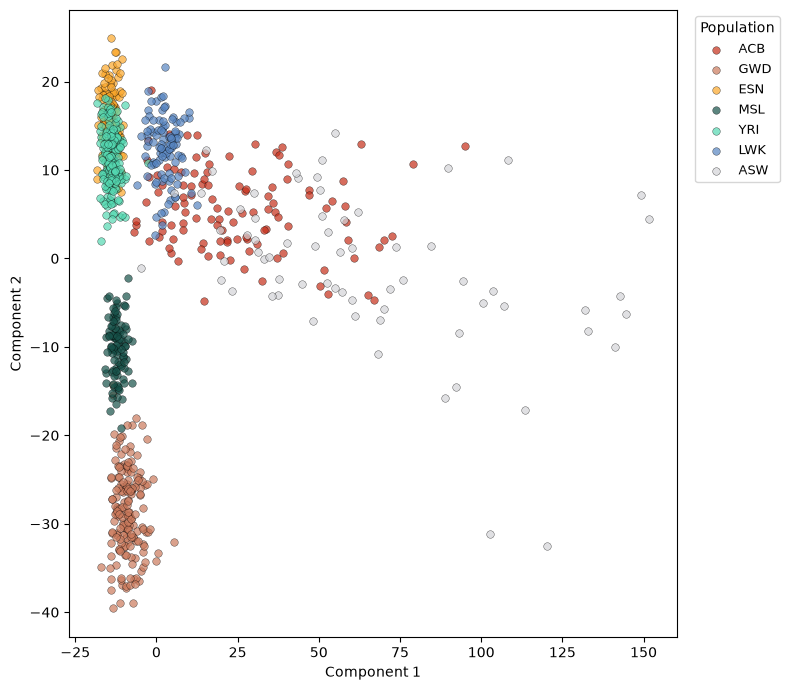

In [205]:
metadata = pd.read_csv('../data/reference_data/igsr_samples.tsv', sep='\t')
sample_col = 'Sample name'
pop_col = 'Population code'
metadata = metadata.set_index(sample_col)
pop_labels = metadata.loc[samples, pop_col]

populations = pop_labels.unique()
colors = ["#C52E19", "#CB7A5C", "#FBA72A", "#175149", "#54D8B1", "#5785C1", "#D3D4D8"]

fig, ax = plt.subplots(figsize=(8, 7))

for i, pop in enumerate(populations):
    mask = (pop_labels == pop).values
    ax.scatter(coords[mask, 0], coords[mask, 1], 
               label=pop, alpha=0.7, s=30, 
               c=colors[i], edgecolor='k', linewidth=0.3)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.legend(title='Population', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('../data/population_visualisation/pca_by_population.png', dpi=150, bbox_inches='tight')
plt.show()

## Identify Outlier Populations

In [206]:
sample_file = "../data/reference_data/igsr_samples.tsv"
outlier_file = "../data/reference_data/outliers.txt"

sample_df = pd.read_csv(sample_file, sep='\t')

with open(outlier_file, "w") as f:
  f.write("HG01783\nNA20274\nNA20299\nNA20314\nHG01880\nHG01881\nNA20278\nHG01988\nNA19921\nNA20129")

lookup_dict = {}
with open(sample_file, "r") as f1:
  for sample in f1:
    cols = sample.strip().split("\t")
    id = cols[0]
    population = cols[3]

    lookup_dict[id] = population

with open(outlier_file, "r") as f2:
    for line in f2:
       sample_id = line.strip()
       if sample_id in lookup_dict:
           match = lookup_dict[sample_id]
           print(f"Population for {sample_id}: {match}")

Population for HG01783: IBS,MSL
Population for NA20274: ASW
Population for NA20299: ASW
Population for NA20314: ASW
Population for HG01880: ACB
Population for HG01881: ACB
Population for NA20278: ASW
Population for HG01988: ACB
Population for NA19921: ASW
Population for NA20129: ASW


### Remove Outliers From Data

In [207]:
pop_dir = "../data/population_data"
pop_dir = Path(pop_dir)

populations = ["YRI", "LWK", "GWD", "MSL", "ESN", "ASW", "ACB"]

clean_samples = set(samples)

for pop in populations:
    infile = pop_dir / f"{pop}/{pop}_samples.txt"
    outfile = pop_dir / f"{pop}/{pop}_samples_clean.txt"

    with open(infile) as f:
        original_ids = [line.strip() for line in f if line.strip()]

    kept_ids = [s for s in original_ids if s in clean_samples]
    removed_ids = [s for s in original_ids if s not in clean_samples]

    with open(outfile, 'w') as f:
        for s in kept_ids:
            f.write(f"{s}\n")

    print(f"{pop}: {len(original_ids)} -> {len(kept_ids)} samples "
          f"({len(removed_ids)} removed)")
    if removed_ids:
        print(f"  Removed: {removed_ids}")

YRI: 178 -> 178 samples (0 removed)
LWK: 99 -> 99 samples (0 removed)
GWD: 178 -> 178 samples (0 removed)
MSL: 100 -> 99 samples (1 removed)
  Removed: ['HG01783']
ESN: 149 -> 149 samples (0 removed)
ASW: 74 -> 67 samples (7 removed)
  Removed: ['NA19625', 'NA19921', 'NA20129', 'NA20274', 'NA20278', 'NA20299', 'NA20314']
ACB: 116 -> 112 samples (4 removed)
  Removed: ['HG01880', 'HG01881', 'HG01988', 'HG02420']


In [208]:
metadata = pd.read_csv('../data/reference_data/igsr_samples.tsv', sep='\t')

sample_col = 'Sample name'

print(f"Original metadata rows: {len(metadata)}")

metadata_clean = metadata[metadata[sample_col].isin(clean_samples)].copy()

print(f"Clean metadata rows: {len(metadata_clean)}")
print(f"Removed: {len(metadata) - len(metadata_clean)}")

missing_from_metadata = clean_samples - set(metadata[sample_col])
if missing_from_metadata:
    print(f"WARNING: {len(missing_from_metadata)} samples in clean_samples "
          f"have no matching row in metadata: {missing_from_metadata}")

metadata_clean.to_csv('../data/reference_data/igsr_samples_clean.tsv', sep='\t', index=False)

Original metadata rows: 894
Clean metadata rows: 882
Removed: 12


In [209]:
%%bash

for pop in ACB ASW ESN GWD LWK MSL YRI; do
    bcftools view -S ../data/population_data/${pop}/${pop}_samples_clean.txt \
      ../data/population_data/${pop}/${pop}_epi_highfreq.vcf.gz \
      -Oz -o ../data/population_data/${pop}/${pop}_epi_highfreq_clean.vcf.gz
    
    bcftools index -t ../data/population_data/${pop}/${pop}_epi_highfreq_clean.vcf.gz
    
    echo "${pop}: done"
done

ACB: done
ASW: done
ESN: done
GWD: done
LWK: done
MSL: done
YRI: done


# Differential Analysis
---
### Per-population Allele Frequency Counts

In [210]:
%%bash

for pop in ACB ASW ESN GWD LWK MSL YRI; do
    plink --vcf ../data/population_data/${pop}/${pop}_epi_highfreq_clean.vcf.gz \
          --freq \
          --set-missing-var-ids @:#:\$1:\$2 \
          --out ../data/differential_analysis/${pop}/${pop}_freq \
          --allow-extra-chr
done

PLINK v1.90p 64-bit (6 Sep 2023)               www.cog-genomics.org/plink/1.9/
(C) 2005-2023 Shaun Purcell, Christopher Chang   GNU General Public License v3
Logging to ../data/differential_analysis/ACB/ACB_freq.log.
Options in effect:
  --allow-extra-chr
  --freq
  --out ../data/differential_analysis/ACB/ACB_freq
  --set-missing-var-ids @:#:$1:$2
  --vcf ../data/population_data/ACB/ACB_epi_highfreq_clean.vcf.gz

24576 MB RAM detected; reserving 12288 MB for main workspace.
--vcf: ../data/differential_analysis/ACB/ACB_freq-temporary.bed +
../data/differential_analysis/ACB/ACB_freq-temporary.bim +
../data/differential_analysis/ACB/ACB_freq-temporary.fam written.
255200 variants loaded from .bim file.
255200 missing IDs set.
112 people (0 males, 0 females, 112 ambiguous) loaded from .fam.
Ambiguous sex IDs written to ../data/differential_analysis/ACB/ACB_freq.nosex .
Using 1 thread (no multithreaded calculations invoked).
Before main variant filters, 112 founders and 0 nonfounders presen

### Merge Into One Matrix

In [211]:
diff_dir = "../data/differential_analysis"
diff_dir = Path(diff_dir)
populations = ['ACB', 'ASW', 'ESN', 'GWD', 'LWK', 'MSL', 'YRI']

freq_dfs = {}
for pop in populations:
    df = pd.read_csv(diff_dir / f"{pop}/{pop}_freq.frq", sep=r'\s+')
    df = df[['CHR', 'SNP', 'A1', 'A2', 'MAF', 'NCHROBS']].rename(columns={
        'A1': f'A1_{pop}', 'A2': f'A2_{pop}', 'MAF': f'MAF_{pop}', 'NCHROBS': f'N_{pop}'
    })
    freq_dfs[pop] = df

merged = freq_dfs[populations[0]]
for pop in populations[1:]:
    cols = ['SNP', f'A1_{pop}', f'A2_{pop}', f'MAF_{pop}', f'N_{pop}']
    merged = merged.merge(freq_dfs[pop][cols], on='SNP', how='outer')

a1_cols = [f'A1_{pop}' for pop in populations]
merged['A1_ref'] = merged[a1_cols].bfill(axis=1).iloc[:, 0]

for pop in populations:
    a1_col, maf_col = f'A1_{pop}', f'MAF_{pop}'
    mismatch = (merged[a1_col].notna()) & (merged[a1_col] != merged['A1_ref'])
    if mismatch.sum() > 0:
        merged.loc[mismatch, maf_col] = 1 - merged.loc[mismatch, maf_col]

required_cols = [f'MAF_{pop}' for pop in populations] + [f'N_{pop}' for pop in populations]
complete_mask = merged[required_cols].notna().all(axis=1)
print(f"Complete-data SNPs: {complete_mask.sum()} / {len(merged)}")

merged = merged[complete_mask].reset_index(drop=True)

final_cols = ['CHR', 'SNP', 'A1_ref'] + [f'MAF_{pop}' for pop in populations]
freq_matrix = merged[final_cols].rename(columns={'A1_ref': 'A1'})
freq_matrix.columns = ['CHR', 'SNP', 'A1'] + populations
freq_matrix.to_csv(pop_dir / 'allele_freq_matrix.csv', index=False)

Complete-data SNPs: 255072 / 255200


### Compute Allele Counts and Run Fisher's Exact Test

In [212]:
pop_pairs = list(combinations(populations, 2))
print(f"{len(pop_pairs)} population pairs, {len(merged)} SNPs -> "
      f"{len(pop_pairs) * len(merged):,} total tests")

results = []

for pop_a, pop_b in pop_pairs:
    n_a = merged[f'N_{pop_a}'].to_numpy()
    n_b = merged[f'N_{pop_b}'].to_numpy()
    maf_a = merged[f'MAF_{pop_a}'].to_numpy()
    maf_b = merged[f'MAF_{pop_b}'].to_numpy()

    alt_a = np.round(maf_a * n_a).astype(np.uint32)
    ref_a = (n_a - alt_a).astype(np.uint32)
    alt_b = np.round(maf_b * n_b).astype(np.uint32)
    ref_b = (n_b - alt_b).astype(np.uint32)

    p_values = fisher.pvalue_npy(ref_a, alt_a, ref_b, alt_b)[2]

    results.append(pd.DataFrame({
        'SNP': merged['SNP'],
        'CHR': merged['CHR'],
        'pop_a': pop_a,
        'pop_b': pop_b,
        'p_value': p_values
    }))

    print(f"{pop_a} vs {pop_b}: done")

all_results = pd.concat(results, ignore_index=True)
print(f"\nTotal tests: {len(all_results):,}")

21 population pairs, 255072 SNPs -> 5,356,512 total tests
ACB vs ASW: done
ACB vs ESN: done
ACB vs GWD: done
ACB vs LWK: done
ACB vs MSL: done
ACB vs YRI: done
ASW vs ESN: done
ASW vs GWD: done
ASW vs LWK: done
ASW vs MSL: done
ASW vs YRI: done
ESN vs GWD: done
ESN vs LWK: done
ESN vs MSL: done
ESN vs YRI: done
GWD vs LWK: done
GWD vs MSL: done
GWD vs YRI: done
LWK vs MSL: done
LWK vs YRI: done
MSL vs YRI: done

Total tests: 5,356,512


### Apply Benjamini-Hochberg Correction

In [213]:
reject, p_adj, _, _ = multipletests(all_results['p_value'], method='fdr_bh', alpha=0.05)
all_results['p_adj_BH'] = p_adj
all_results['bh_significant'] = reject

print(f"SNP×pair tests passing BH < 0.05: {reject.sum():,} / {len(all_results):,}")

SNP×pair tests passing BH < 0.05: 502,872 / 5,356,512


### Compute Per-SNP FST for Each Population Pair

In [214]:
%%bash

pops=(ACB ASW ESN GWD LWK MSL YRI)

for i in "${!pops[@]}"; do
    for j in "${!pops[@]}"; do
        if [ "$j" -gt "$i" ]; then
            pop_a=${pops[$i]}
            pop_b=${pops[$j]}

            bcftools merge ../data/population_data/${pop_a}/${pop_a}_epi_highfreq_clean.vcf.gz \
                           ../data/population_data/${pop_b}/${pop_b}_epi_highfreq_clean.vcf.gz \
                           -Oz -o ../data/differential_analysis/merged/merged_${pop_a}_${pop_b}.vcf.gz
            bcftools index -t ../data/differential_analysis/merged/merged_${pop_a}_${pop_b}.vcf.gz

            vcftools --gzvcf ../data/differential_analysis/merged/merged_${pop_a}_${pop_b}.vcf.gz \
                      --weir-fst-pop ../data/population_data/${pop_a}/${pop_a}_samples_clean.txt \
                      --weir-fst-pop ../data/population_data/${pop_b}/${pop_b}_samples_clean.txt \
                      --out ../data/differential_analysis/fst/fst_${pop_a}_vs_${pop_b}
        fi
    done
done


VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--gzvcf ../data/differential_analysis/merged/merged_ACB_ASW.vcf.gz
	--weir-fst-pop ../data/population_data/ACB/ACB_samples_clean.txt
	--weir-fst-pop ../data/population_data/ASW/ASW_samples_clean.txt
	--keep ../data/population_data/ACB/ACB_samples_clean.txt
	--keep ../data/population_data/ASW/ASW_samples_clean.txt
	--out ../data/differential_analysis/fst/fst_ACB_vs_ASW

Using zlib version: 1.2.12
Keeping individuals in 'keep' list
After filtering, kept 179 out of 179 Individuals
Outputting Weir and Cockerham Fst estimates.
Weir and Cockerham mean Fst estimate: 0.0039499
Weir and Cockerham weighted Fst estimate: 0.0038721
After filtering, kept 255200 out of a possible 255200 Sites
Run Time = 4.00 seconds

VCFtools - 0.1.17
(C) Adam Auton and Anthony Marcketta 2009

Parameters as interpreted:
	--gzvcf ../data/differential_analysis/merged/merged_ACB_ESN.vcf.gz
	--weir-fst-pop ../data/population_data/A

### Load FST Results, Compute Per-Pair 95th Percentile, and Merge Into Main Results Table

In [215]:
fst_all = []

for pop_a, pop_b in pop_pairs:
    fst_file = diff_dir / f"fst/fst_{pop_a}_vs_{pop_b}.weir.fst"
    fst_df = pd.read_csv(fst_file, sep='\t')
    fst_df = fst_df.rename(columns={'WEIR_AND_COCKERHAM_FST': 'fst'})
    fst_df['pop_a'] = pop_a
    fst_df['pop_b'] = pop_b
    fst_df['CHROM_POS'] = fst_df['CHROM'].astype(str) + ':' + fst_df['POS'].astype(str)
    fst_all.append(fst_df[['CHROM_POS', 'pop_a', 'pop_b', 'fst']])

fst_combined = pd.concat(fst_all, ignore_index=True)

pct95_by_pair = fst_combined.groupby(['pop_a', 'pop_b'])['fst'].quantile(0.95).rename('fst_95pct')
fst_combined = fst_combined.merge(pct95_by_pair, on=['pop_a', 'pop_b'])
fst_combined['fst_exceeds_95pct'] = fst_combined['fst'] > fst_combined['fst_95pct']

### Merge FST into Fisher/BH Results and Classify "Significantly Differentially Abundant" SNPs

In [216]:
all_results['CHROM_POS'] = all_results['SNP'].str.split(':').str[:2].str.join(':')

final = all_results.merge(fst_combined, on=['CHROM_POS', 'pop_a', 'pop_b'], how='inner')

final['significantly_differentiated'] = final['bh_significant'] & final['fst_exceeds_95pct']

print(f"SNP×pair combinations classified as significantly differentiated: "
      f"{final['significantly_differentiated'].sum():,} / {len(final):,}")

final.to_csv(diff_dir / 'differentiation_results.csv', index=False)

SNP×pair combinations classified as significantly differentiated: 246,574 / 5,356,512


### Percentage of Significantly Differentiated SNPs Per Pair

   pop_a pop_b  n_bh_sig  pct_significant
11   ESN   GWD     37494        14.699379
15   GWD   LWK     36948        14.485322
7    ASW   GWD     34855        13.664769
6    ASW   ESN     33061        12.961438
10   ASW   YRI     32921        12.906552
17   GWD   YRI     31929        12.517642
2    ACB   GWD     30877        12.105210
9    ASW   MSL     27509        10.784798
19   LWK   YRI     26014        10.198689
12   ESN   LWK     25433         9.970910
18   LWK   MSL     22017         8.631680
5    ACB   YRI     21983         8.618351
8    ASW   LWK     21812         8.551311
1    ACB   ESN     21089         8.267862
13   ESN   MSL     20241         7.935406
4    ACB   MSL     17684         6.932944
3    ACB   LWK     16733         6.560109
20   MSL   YRI     16674         6.536978
16   GWD   MSL     14040         5.504328
14   ESN   YRI      7799         3.057568
0    ACB   ASW      5759         2.257794


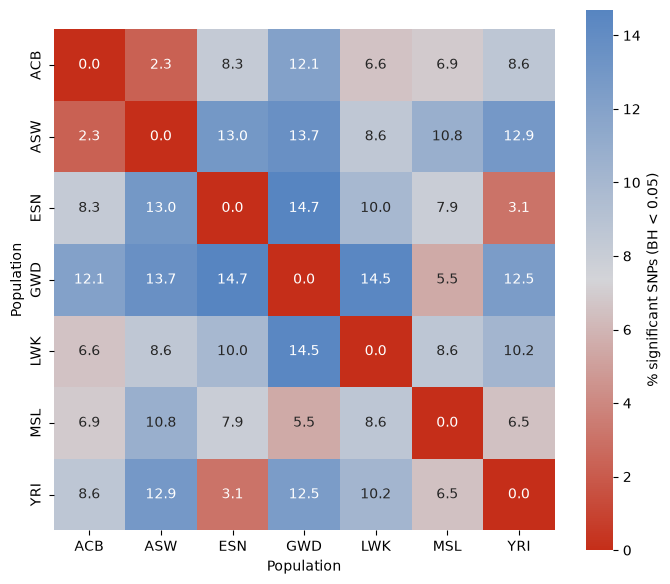

In [217]:
populations = ['ACB', 'ASW', 'ESN', 'GWD', 'LWK', 'MSL', 'YRI']

n_total_snps = merged.shape[0]

bh_counts = final[final['bh_significant']].groupby(['pop_a', 'pop_b']).size().reset_index(name='n_bh_sig')
bh_counts['pct_significant'] = bh_counts['n_bh_sig'] / n_total_snps * 100

print(bh_counts.sort_values('pct_significant', ascending=False))

pct_matrix = pd.DataFrame(np.nan, index=populations, columns=populations)
for _, row in bh_counts.iterrows():
    pct_matrix.loc[row['pop_a'], row['pop_b']] = row['pct_significant']
    pct_matrix.loc[row['pop_b'], row['pop_a']] = row['pct_significant']
np.fill_diagonal(pct_matrix.values, 0)

custom_cmap = sns.blend_palette(
    ["#C52E19", "#D3D4D8", "#5785C1"], as_cmap=True
)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(pct_matrix.astype(float), annot=True, fmt='.1f', cmap=custom_cmap,
            square=True, cbar_kws={'label': '% significant SNPs (BH < 0.05)'}, ax=ax)
plt.xlabel('Population')
plt.ylabel('Population')
plt.tight_layout()
plt.savefig('../data/differential_analysis/pct_significant_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

### Clustermap

/Users/sonalinaidoo/Documents/Bioinformatics/project/.venv/lib/python3.14/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
/Users/sonalinaidoo/Documents/Bioinformatics/project/.venv/lib/python3.14/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


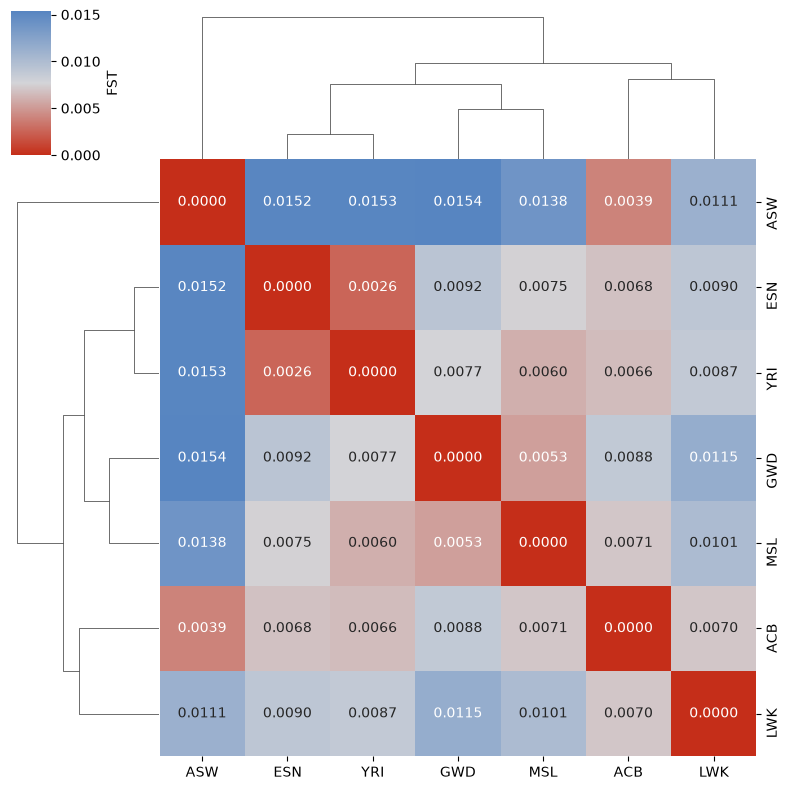

In [218]:
populations = ['ACB', 'ASW', 'ESN', 'GWD', 'LWK', 'MSL', 'YRI']

pair_means = fst_combined.groupby(['pop_a', 'pop_b'])['fst'].mean().reset_index()

fst_matrix = pd.DataFrame(np.nan, index=populations, columns=populations)
for _, row in pair_means.iterrows():
    fst_matrix.loc[row['pop_a'], row['pop_b']] = row['fst']
    fst_matrix.loc[row['pop_b'], row['pop_a']] = row['fst']  # symmetric
np.fill_diagonal(fst_matrix.values, 0)

fst_matrix_clean = fst_matrix.astype(float)

custom_cmap = sns.blend_palette(
    ["#C52E19", "#D3D4D8", "#5785C1"], as_cmap=True
)

clustergram = sns.clustermap(
    fst_matrix_clean,
    annot=True, fmt='.4f',
    cmap=custom_cmap,
    method='average',       # UPGMA linkage
    metric='euclidean',     # distance metric on the FST values themselves
    figsize=(8, 8),
    cbar_kws={'label': 'FST'}
)
plt.savefig('../data/differential_analysis/fst_clustergram.png', dpi=150, bbox_inches='tight')
plt.show()

### Bar Chart of Significantly Differentiated SNPs Per Pair

   pop_a pop_b  n_significant        pair
11   ESN   GWD          37494  ESN vs GWD
15   GWD   LWK          36948  GWD vs LWK
7    ASW   GWD          34855  ASW vs GWD
6    ASW   ESN          33061  ASW vs ESN
10   ASW   YRI          32921  ASW vs YRI
17   GWD   YRI          31929  GWD vs YRI
2    ACB   GWD          30877  ACB vs GWD
9    ASW   MSL          27509  ASW vs MSL
19   LWK   YRI          26014  LWK vs YRI
12   ESN   LWK          25433  ESN vs LWK
18   LWK   MSL          22017  LWK vs MSL
5    ACB   YRI          21983  ACB vs YRI
8    ASW   LWK          21812  ASW vs LWK
1    ACB   ESN          21089  ACB vs ESN
13   ESN   MSL          20241  ESN vs MSL
4    ACB   MSL          17684  ACB vs MSL
3    ACB   LWK          16733  ACB vs LWK
20   MSL   YRI          16674  MSL vs YRI
16   GWD   MSL          14040  GWD vs MSL
14   ESN   YRI           7799  ESN vs YRI
0    ACB   ASW           5759  ACB vs ASW


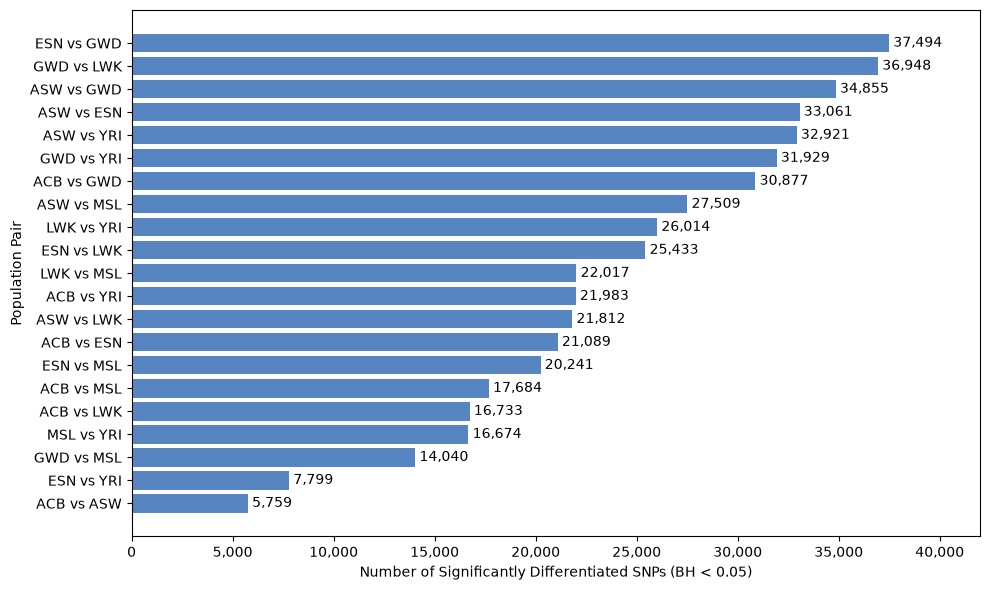

In [219]:
sig_counts = (final[final['bh_significant'].astype(bool)]
              .groupby(['pop_a', 'pop_b']).size().reset_index(name='n_significant'))
sig_counts['pair'] = sig_counts['pop_a'] + ' vs ' + sig_counts['pop_b']
sig_counts = sig_counts.sort_values('n_significant', ascending=False)

print(sig_counts)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(sig_counts['pair'], sig_counts['n_significant'], color='#5785C1')
ax.bar_label(bars, labels=[f'{v:,}' for v in sig_counts['n_significant']], padding=3)
ax.invert_yaxis()
ax.set_xlim(0, sig_counts['n_significant'].max() * 1.12)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_xlabel('Number of Significantly Differentiated SNPs (BH < 0.05)')
ax.set_ylabel('Population Pair')
plt.tight_layout()
plt.savefig('../data/differential_analysis/significant_snps_per_pair.png', dpi=150, bbox_inches='tight')
plt.show()

# Disease Characterisation
---
### Build List of Significantly Differentiated SNPs Across Multiple Pairs

In [220]:
sig_results = final[final['significantly_differentiated']]

snp_pair_counts = sig_results.groupby('SNP').agg(
    n_pairs=('pop_a', 'count'),
    pairs=('pop_a', lambda x: list(zip(sig_results.loc[x.index, 'pop_a'], sig_results.loc[x.index, 'pop_b'])))
).reset_index()

multi_pair_snps = snp_pair_counts[snp_pair_counts['n_pairs'] >= 7].sort_values('n_pairs', ascending=False)
print(f"SNPs significant in >=7 population pairs: {len(multi_pair_snps)}")
print(multi_pair_snps.head(10))

multi_pair_snps = multi_pair_snps.merge(
    sig_results[['SNP', 'CHR', 'CHROM_POS']].drop_duplicates(), on='SNP'
)
multi_pair_snps['is_rsid'] = multi_pair_snps['SNP'].str.startswith('rs')
print(multi_pair_snps['is_rsid'].value_counts())

multi_pair_snps['pos'] = multi_pair_snps['SNP'].str.split(':').str[1].astype(int)
multi_pair_snps['CHR'] = multi_pair_snps['CHR'].astype(str)

multi_pair_snps.to_csv('../data/differential_analysis/multi_pair_significant_snps.csv', index=False)

SNPs significant in >=7 population pairs: 5043
                       SNP  n_pairs  \
92659     chr9:1931649:C:G       14   
87574    chr7:96438231:C:T       13   
32003    chr17:6729682:C:G       12   
10886  chr12:124341046:C:T       12   
51338    chr1:58787944:A:G       12   
35656    chr19:1078102:A:G       12   
35601    chr19:1060488:G:T       12   
35598    chr19:1059005:A:G       12   
20057   chr14:72692035:C:G       12   
56216   chr2:230469048:A:G       12   

                                                   pairs  
92659  [(ACB, ASW), (ACB, ESN), (ACB, MSL), (ACB, YRI...  
87574  [(ACB, ASW), (ACB, LWK), (ACB, MSL), (ASW, ESN...  
32003  [(ACB, ESN), (ACB, GWD), (ACB, MSL), (ACB, YRI...  
10886  [(ACB, ESN), (ACB, GWD), (ACB, MSL), (ACB, YRI...  
51338  [(ACB, ASW), (ACB, ESN), (ACB, LWK), (ACB, MSL...  
35656  [(ACB, ESN), (ACB, GWD), (ACB, MSL), (ACB, YRI...  
35601  [(ACB, ESN), (ACB, GWD), (ACB, MSL), (ACB, YRI...  
35598  [(ACB, ESN), (ACB, GWD), (ACB, MSL), (ACB, Y

### Top Genes with Significantly Differentially Abundant SNPs

255,072 SNPs tested | 95,212 significant in >= 1 pair | 5,043 significant in >= 7 pairs
449 genes with >= 1 significantly differentiated SNP (body+flank); 336 with >= 1 SNP in >= 7 pairs


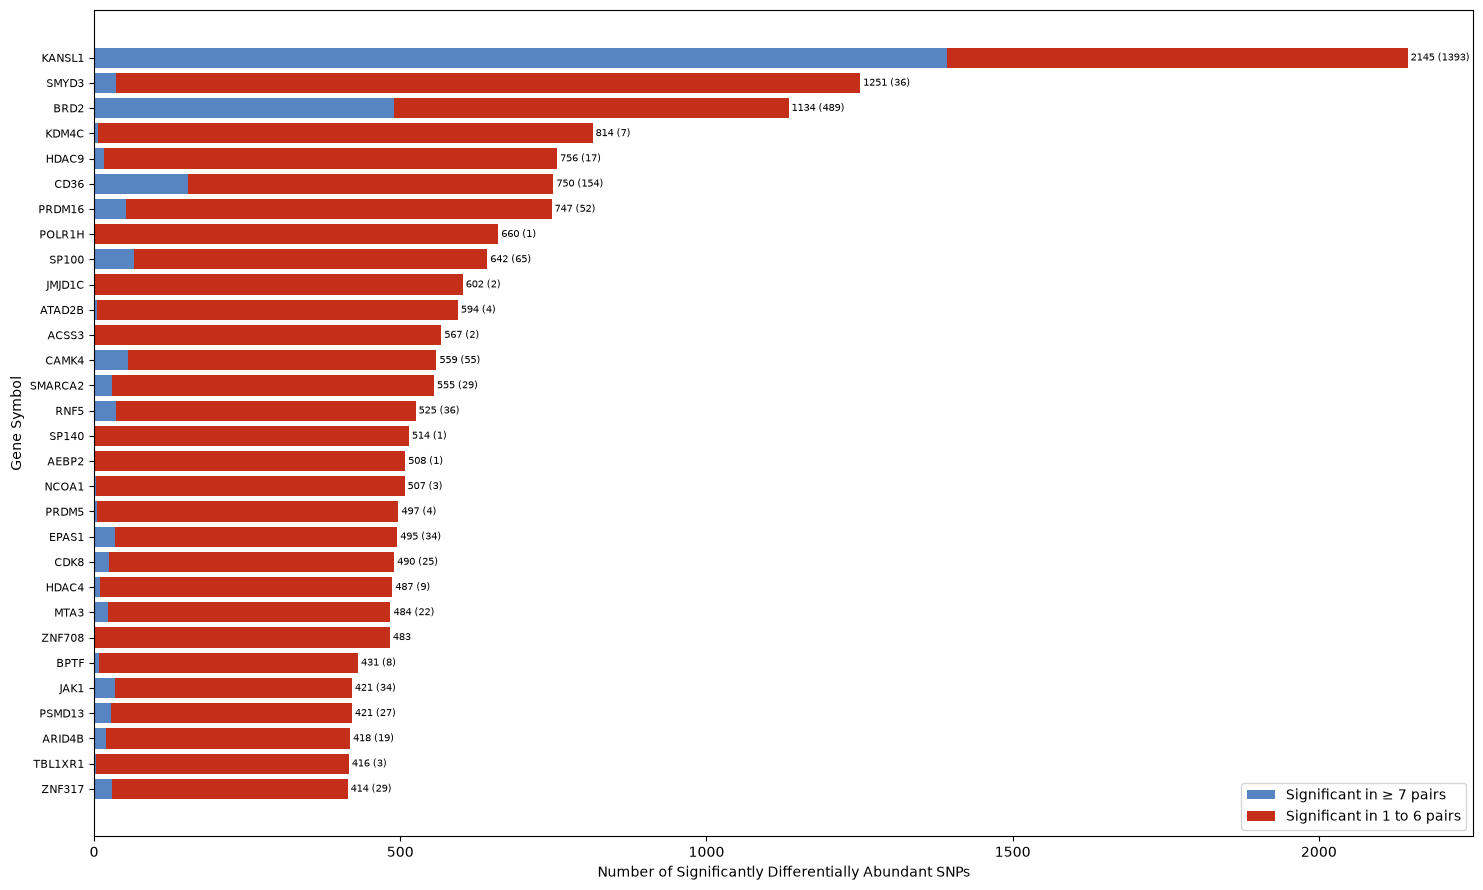

In [221]:
min_pairs = 7                
gene_region = 'body+flank' 
window = 100_000
top_genes = 30            

final['_sig'] = final['significantly_differentiated'].astype(bool)

snp_sig = final.groupby('CHROM_POS')['_sig'].sum().rename('n_sig_pairs').reset_index()
snp_sig['sig_any'] = snp_sig['n_sig_pairs'] >= 1
snp_sig['sig_multi'] = snp_sig['n_sig_pairs'] >= min_pairs
snp_sig['chrom'] = snp_sig['CHROM_POS'].str.split(':').str[0].str.replace('chr', '', regex=False)
snp_sig['pos'] = snp_sig['CHROM_POS'].str.split(':').str[1].astype(int)
print(f"{len(snp_sig):,} SNPs tested | {snp_sig['sig_any'].sum():,} significant in >= 1 pair | "
      f"{snp_sig['sig_multi'].sum():,} significant in >= {min_pairs} pairs")

genes = pd.read_csv('../data/coordinate_data/gene_coordinates.csv')
genes = genes.dropna(subset=['chrom', 'start', 'end']).drop_duplicates('symbol').copy()
genes['chrom'] = genes['chrom'].astype(str).str.replace('chr', '', regex=False)
genes[['start', 'end']] = genes[['start', 'end']].astype(int)
pad = window if gene_region == 'body+flank' else 0

rows = []
for chrom, s in snp_sig.groupby('chrom'):
    pos = s['pos'].to_numpy()
    for g in genes[genes['chrom'] == chrom].itertuples():
        hit = np.where((pos >= g.start - pad) & (pos <= g.end + pad))[0]
        if len(hit):
            rows.append(pd.DataFrame({'symbol': g.symbol, 'CHROM_POS': s['CHROM_POS'].to_numpy()[hit]}))
snp_gene_diff = pd.concat(rows, ignore_index=True).merge(
    snp_sig[['CHROM_POS', 'sig_any', 'sig_multi']], on='CHROM_POS')

gene_counts = (snp_gene_diff.groupby('symbol')
                 .agg(n_snps_tested=('CHROM_POS', 'size'),
                      n_sig_any=('sig_any', 'sum'),
                      n_sig_multi=('sig_multi', 'sum'))
                 .sort_values('n_sig_any', ascending=False))
gene_counts.to_csv('../data/gene_annotation/sig_snps_per_gene.csv')
print(f"{(gene_counts['n_sig_any'] > 0).sum()} genes with >= 1 significantly differentiated SNP "
      f"({gene_region}); {(gene_counts['n_sig_multi'] > 0).sum()} with >= 1 SNP in >= {min_pairs} pairs")

gene_counts['n_sig_few'] = gene_counts['n_sig_any'] - gene_counts['n_sig_multi']

top = gene_counts[gene_counts['n_sig_any'] > 0].head(top_genes)
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(15, 9))
ax.barh(y, top['n_sig_multi'], color='#5785C1', label=f'Significant in ≥ {min_pairs} pairs')
ax.barh(y, top['n_sig_few'], left=top['n_sig_multi'], color='#C52E19',
        label=f'Significant in 1 to {min_pairs - 1} pairs')
for i, (tot, multi) in enumerate(zip(top['n_sig_any'], top['n_sig_multi'])):
    ax.text(tot, i, f' {int(tot)}' + (f' ({int(multi)})' if multi else ''), va='center', fontsize=7)
ax.set_yticks(y, top.index, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('Number of Significantly Differentially Abundant SNPs')
ax.set_ylabel('Gene Symbol')

ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../data/differential_analysis/sig_snps_per_gene.png', dpi=150, bbox_inches='tight')
plt.show()

### Query GWAS

In [222]:
gwas_full = pd.read_csv('../data/reference_data/gwas_catalog_associations.tsv', sep='\t', low_memory=False)
print(gwas_full.columns.tolist())

gwas_full['CHR_ID'] = gwas_full['CHR_ID'].astype(str)
gwas_full['CHR_POS'] = pd.to_numeric(gwas_full['CHR_POS'], errors='coerce')
gwas_full = gwas_full.dropna(subset=['CHR_POS'])
gwas_full['CHR_POS'] = gwas_full['CHR_POS'].astype(int)

gwas_matches = multi_pair_snps[['SNP', 'CHR', 'pos']].merge(
    gwas_full, left_on=['CHR', 'pos'], right_on=['CHR_ID', 'CHR_POS'], how='inner'
)
print(f"GWAS Catalog position matches: {len(gwas_matches)} rows, {gwas_matches['SNP'].nunique()} unique SNPs")
gwas_matches.to_csv('../data/disease_characterisation/gwas_catalog_matches_raw.csv', index=False)

['DATE ADDED TO CATALOG', 'PUBMEDID', 'FIRST AUTHOR', 'DATE', 'JOURNAL', 'LINK', 'STUDY', 'DISEASE/TRAIT', 'INITIAL SAMPLE SIZE', 'REPLICATION SAMPLE SIZE', 'REGION', 'CHR_ID', 'CHR_POS', 'REPORTED GENE(S)', 'MAPPED_GENE', 'UPSTREAM_GENE_ID', 'DOWNSTREAM_GENE_ID', 'SNP_GENE_IDS', 'UPSTREAM_GENE_DISTANCE', 'DOWNSTREAM_GENE_DISTANCE', 'STRONGEST SNP-RISK ALLELE', 'SNPS', 'MERGED', 'SNP_ID_CURRENT', 'CONTEXT', 'INTERGENIC', 'RISK ALLELE FREQUENCY', 'P-VALUE', 'PVALUE_MLOG', 'P-VALUE (TEXT)', 'OR or BETA', '95% CI (TEXT)', 'PLATFORM [SNPS PASSING QC]', 'CNV', 'MAPPED_TRAIT', 'MAPPED_TRAIT_URI', 'STUDY ACCESSION', 'GENOTYPING TECHNOLOGY']
GWAS Catalog position matches: 1777 rows, 630 unique SNPs


In [223]:
gwas_parsed = gwas_matches.rename(columns={
    'MAPPED_TRAIT': 'trait', 'P-VALUE': 'p_value',
    'REPORTED GENE(S)': 'reported_gene', 'STUDY ACCESSION': 'study_accession'
})

gwas_summary = gwas_parsed.groupby('SNP').agg({
    'trait': lambda x: '; '.join(x.dropna().astype(str).unique()),
    'p_value': lambda x: '; '.join(x.dropna().astype(str).unique()),
    'reported_gene': lambda x: '; '.join(x.dropna().astype(str).unique()),
    'study_accession': lambda x: '; '.join(x.dropna().astype(str).unique())
}).reset_index().rename(columns={
    'trait': 'gwas_traits', 'p_value': 'gwas_p_values',
    'reported_gene': 'gwas_genes', 'study_accession': 'gwas_studies'
})
gwas_summary.to_csv('../data/disease_characterisation/gwas_catalog_parsed.csv', index=False)

### Query ClinVar

In [224]:
%%bash

bcftools query -f '%CHROM\t%POS\t%ID\t%INFO/CLNSIG\t%INFO/CLNDN\t%INFO/CLNDISDB\t%INFO/CLNREVSTAT\n' \
    ../data/reference_data/clinvar.vcf.gz > ../data/disease_characterisation/clinvar_by_position.tsv

In [225]:
clinvar_by_pos = pd.read_csv(
    '../data/disease_characterisation/clinvar_by_position.tsv', sep='\t', header=None,
    names=['CHROM', 'POS', 'variation_id', 'clinical_significance',
           'condition', 'condition_ids', 'review_status'],
    na_values='.', dtype={'CHROM': str}, low_memory=False,
)

clinvar_matches = multi_pair_snps[['SNP', 'CHR', 'pos']].merge(
    clinvar_by_pos, left_on=['CHR', 'pos'], right_on=['CHROM', 'POS'], how='inner'
)

In [226]:
clinvar_matches['condition'] = clinvar_matches['condition'].str.replace('|', '; ', regex=False)

clinvar_summary = clinvar_matches.groupby('SNP').agg({
    'clinical_significance': lambda x: '; '.join(x.dropna().astype(str).unique()),
    'condition': lambda x: '; '.join(x.dropna().astype(str).unique()),
    'review_status': lambda x: '; '.join(x.dropna().astype(str).unique())
}).reset_index().rename(columns={
    'clinical_significance': 'clinvar_significance',
    'condition': 'clinvar_condition',
    'review_status': 'clinvar_review_status'
})
clinvar_summary.to_csv('../data/disease_characterisation/clinvar_parsed.csv', index=False)

### Merge GWAS and ClinVar Results

In [227]:
annotation_table = multi_pair_snps[['SNP', 'CHR', 'pos', 'n_pairs', 'pairs']].copy()
annotation_table = annotation_table.merge(gwas_summary, on='SNP', how='left')
annotation_table = annotation_table.merge(clinvar_summary, on='SNP', how='left')
annotation_table.to_csv('../data/disease_characterisation/disease_annotation_table.csv', index=False)
print(f"Final annotation table: {len(annotation_table)} SNPs")

Final annotation table: 5043 SNPs


### Plot SNP Counts for Annotation Categories

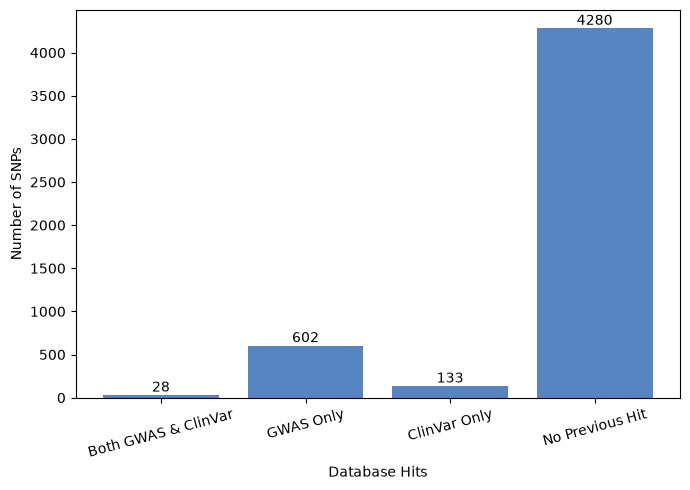

In [228]:
annotation_table['has_gwas_hit'] = annotation_table['gwas_traits'].notna() & (annotation_table['gwas_traits'] != '')
annotation_table['has_clinvar_hit'] = annotation_table['clinvar_significance'].notna() & (annotation_table['clinvar_significance'] != '')
annotation_table['novel_candidate'] = ~(annotation_table['has_gwas_hit'] | annotation_table['has_clinvar_hit'])

categories = pd.Series({
    'Both GWAS & ClinVar': ((annotation_table['has_gwas_hit']) & (annotation_table['has_clinvar_hit'])).sum(),
    'GWAS Only': ((annotation_table['has_gwas_hit']) & (~annotation_table['has_clinvar_hit'])).sum(),
    'ClinVar Only': ((~annotation_table['has_gwas_hit']) & (annotation_table['has_clinvar_hit'])).sum(),
    'No Previous Hit': annotation_table['novel_candidate'].sum()
})

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(categories.index, categories.values, color="#5785C1")
ax.set_xlabel('Database Hits')
ax.set_ylabel('Number of SNPs')
for i, v in enumerate(categories.values):
    ax.text(i, v + max(categories.values)*0.01, str(v), ha='center')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('../data/disease_characterisation/annotation_overview.png', dpi=150, bbox_inches='tight')
plt.show()

### Plot Most Common GWAS Catalog Traits

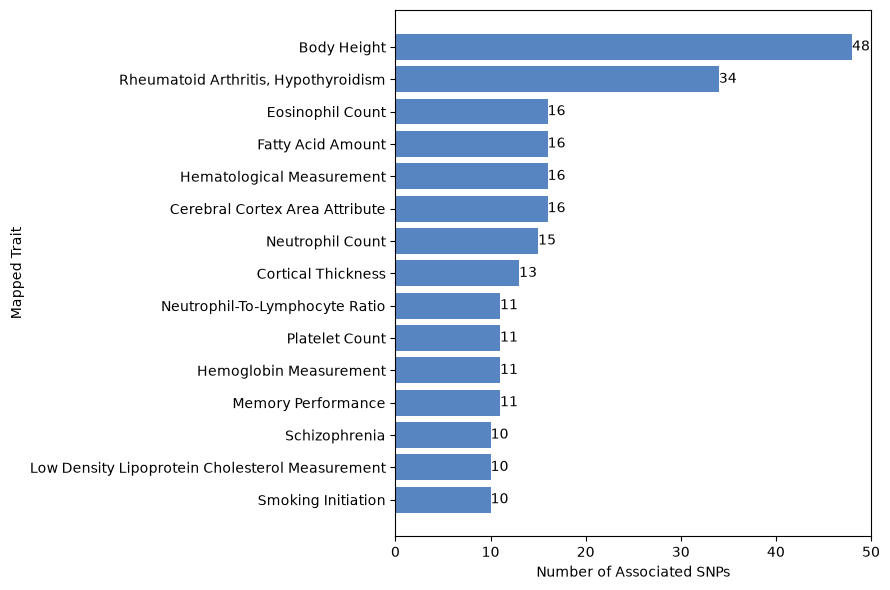

In [229]:
all_traits = annotation_table['gwas_traits'].dropna().str.split('; ').explode()
all_traits = all_traits[all_traits != '']

top_traits = all_traits.value_counts().head(15)

traits = top_traits.index[::-1]
traits = [trait.title() for trait in traits]

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(traits, top_traits.values[::-1], color='#5785C1')
ax.set_xlabel('Number of Associated SNPs')
ax.set_ylabel('Mapped Trait')
ax.bar_label(bars)
ax.set_xlim(right=50)
plt.tight_layout()
plt.savefig('../data/disease_characterisation/top_gwas_traits.png', dpi=150, bbox_inches='tight')
plt.show()

### Plot ClinVar Clinical Significance

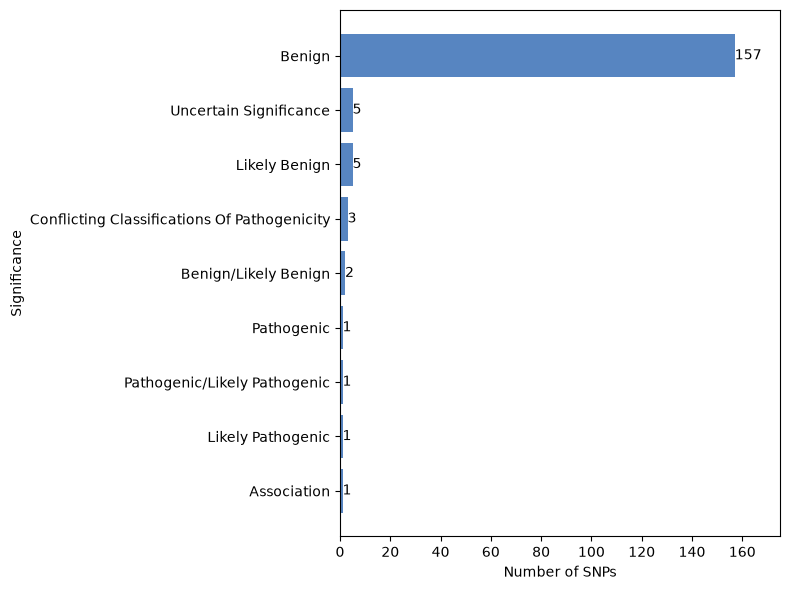

In [230]:
all_clinsig = annotation_table['clinvar_significance'].dropna().str.split('; ').explode()
all_clinsig = all_clinsig[all_clinsig != '']

clinsig_counts = all_clinsig.value_counts()

significances = clinsig_counts.index[::-1]
significances = [significance.title() for significance in significances]
significances = [significance.replace('_', ' ') if isinstance(significance, str) else significance for significance in significances]

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(significances, clinsig_counts.values[::-1], color='#5785C1')
ax.set_xlabel('Number of SNPs')
ax.set_ylabel('Significance')
ax.bar_label(bars)
ax.set_xlim(right=175)
plt.tight_layout()
plt.savefig('../data/disease_characterisation/clinvar_significance_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()

### Plot ClinVar Conditions

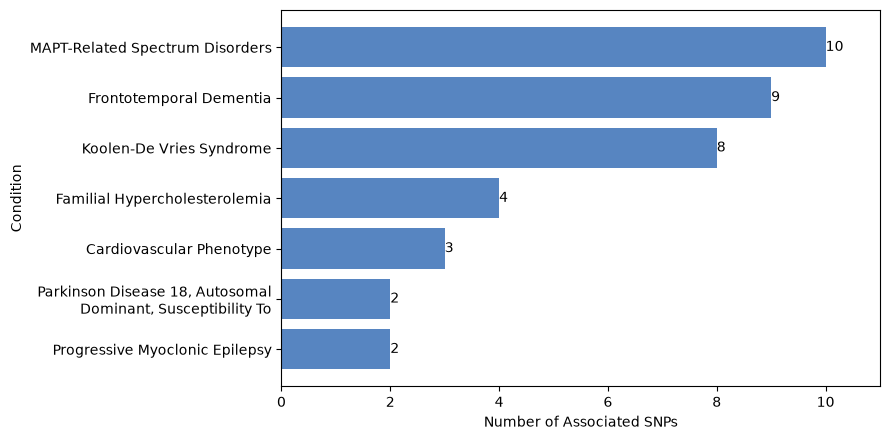

In [231]:
placeholders = {'not provided', 'not specified', 'see cases'}
keep_dbs = {'MedGen', 'OMIM', 'MONDO', 'Orphanet'}

def condition_key(text):
    """Order-, punctuation- and numeric-suffix-insensitive name key."""
    t = re.sub(r'[^\w\s]', ' ', text.lower())
    return ' '.join(sorted(w for w in t.split() if not w.isdigit()))

cm = clinvar_matches[['SNP', 'condition', 'condition_ids']].dropna(subset=['condition']).copy()
names = cm['condition'].str.split(r'\s*[|;]\s*', regex=True)
ids   = cm['condition_ids'].fillna('').str.split('|')

aligned = names.str.len() == ids.str.len()
cm['condition'] = names
cm['condition_ids'] = [i if ok else [''] * len(n) for i, n, ok in zip(ids, names, aligned)]
cm = cm.explode(['condition', 'condition_ids'])

cm['condition'] = cm['condition'].str.strip().str.replace('_', ' ')
cm = cm[(cm['condition'] != '') & ~cm['condition'].str.lower().isin(placeholders)]

def parse_ids(s):
    out = set()
    for token in s.split(','):
        db, _, ident = token.partition(':')
        if db in keep_dbs and ident:
            out.add(f'{db}:{ident}')
    return sorted(out)

cm['ids'] = [parse_ids(s) + ['name:' + condition_key(c)]
             for s, c in zip(cm['condition_ids'], cm['condition'])]

rules = [
    (r'supranuclear palsy', 'rule:psp'),
]

def add_rules(row_ids, cond):
    low = cond.lower()
    extra = [token for pat, token in rules if re.search(pat, low)]
    return row_ids + extra

cm['ids'] = [add_rules(i, c) for i, c in zip(cm['ids'], cm['condition'])]

parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

for ids in cm['ids']:
    for other in ids[1:]:
        parent[find(other)] = find(ids[0])

def group_key(row):
    return find(row['ids'][0])

cm['group'] = cm.apply(group_key, axis=1)

label_for = cm.groupby('group')['condition'].agg(lambda s: s.value_counts().index[0])

acronyms = {'Mapt': 'MAPT', 'Copd': 'COPD', 'Xy': 'XY', 'Iii': 'III',
            'Ago2': 'AGO2', 'Dnhd1': 'DNHD1'}
def prettify(s):
    return re.sub(r'\b(' + '|'.join(acronyms) + r')\b',
                  lambda m: acronyms[m.group(1)], s.title())

min_snps = 2

counts = (cm.drop_duplicates(['SNP', 'group'])
            .groupby('group')['SNP'].nunique()
            .rename('n').reset_index()
            .query('n >= @min_snps')
            .assign(label=lambda d: d['group'].map(label_for))
            .sort_values(['n', 'label'], ascending=[False, True])
            .set_index('group')['n'])

labels = [textwrap.fill(prettify(label_for[g]), 40) for g in counts.index]

fig, ax = plt.subplots(figsize=(9, max(3, 0.5 * len(counts) + 1)))
bars = ax.barh(labels[::-1], counts.values[::-1], color='#5785C1')
ax.set_xlabel('Number of Associated SNPs')
ax.set_ylabel('Condition')
ax.bar_label(bars)
ax.set_xlim(right=counts.max() + 1)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig('../data/disease_characterisation/top_clinvar_conditions.png', dpi=150, bbox_inches='tight')
plt.show()

# Gene Annotation
---
### Format SNPs for VEP

In [232]:
out_dir = '../data/gene_annotation'
co_dir = '../data/cooccurrence_analysis'
window = 100000

snp_list = annotation_table[['SNP']].drop_duplicates().copy()
snp_list['snp_key'] = snp_list['SNP'].str.split(':').str[:2].str.join(':')
snp_list = snp_list.drop_duplicates('snp_key')
snp_list['CHR'] = snp_list['snp_key'].str.split(':').str[0]
snp_list['POS'] = snp_list['snp_key'].str.split(':').str[1].astype(int)

bed = pd.DataFrame({'c': snp_list['CHR'], 's': snp_list['POS'] - 1, 'e': snp_list['POS']})
bed.to_csv(f'{out_dir}/vep_sites.bed', sep='\t', header=False, index=False)
bed.to_csv(f'{co_dir}/sig_snps.bed', sep='\t', header=False, index=False)
print(f"{len(snp_list):,} unique SNP positions")

5,043 unique SNP positions


In [233]:
%%bash

bcftools query -R ../data/gene_annotation/vep_sites.bed \
  -f '%CHROM\t%POS\t%REF\t%ALT\n' \
  ../data/population_data/ACB/ACB_epi_highfreq_clean.vcf.gz \
  > ../data/gene_annotation/vep_site_alleles.tsv

In [234]:
alleles = pd.read_csv(f'{out_dir}/vep_site_alleles.tsv', sep='\t', header=None,
                 names=['CHROM', 'POS', 'REF', 'ALT'], dtype=str)
alleles['snp_key'] = alleles['CHROM'] + ':' + alleles['POS']
print(f"{alleles['snp_key'].duplicated().sum()} duplicate positions (multiallelic), keeping first")
al = alleles.drop_duplicates('snp_key')
missing = set(snp_list['snp_key']) - set(al['snp_key'])
print(f"SNPs not found in VCF: {len(missing)}")

with open(f'{out_dir}/vep_input.vcf', 'w') as f:
    f.write('##fileformat=VCFv4.2\n#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO\n')
    for r in al.itertuples():
        f.write(f"{r.CHROM.replace('chr', '')}\t{r.POS}\t{r.snp_key}\t{r.REF}\t{r.ALT}\t.\t.\t.\n")

0 duplicate positions (multiallelic), keeping first
SNPs not found in VCF: 0


### Build Gene Body and Flank Tracks

In [235]:
gene_file = pd.read_csv('../data/coordinate_data/gene_coordinates.csv')
epi_genes = (gene_file.dropna(subset=['chrom', 'start', 'end'])
                      .drop_duplicates('symbol').copy())
epi_genes['chrom'] = epi_genes['chrom'].astype(str).str.replace('chr', '', regex=False)
epi_genes[['start', 'end']] = epi_genes[['start', 'end']].astype(int)    # Ensembl: 1-based, inclusive

body = pd.DataFrame({'chrom': epi_genes['chrom'], 'start': epi_genes['start'] - 1,
                     'end': epi_genes['end'], 'symbol': epi_genes['symbol']})

left = pd.DataFrame({'chrom': epi_genes['chrom'],
                     'start': (epi_genes['start'] - 1 - window).clip(lower=0),
                     'end': epi_genes['start'] - 1, 'symbol': epi_genes['symbol']})
right = pd.DataFrame({'chrom': epi_genes['chrom'], 'start': epi_genes['end'],
                      'end': epi_genes['end'] + window, 'symbol': epi_genes['symbol']})
flank = pd.concat([left, right], ignore_index=True)
flank = flank[flank['end'] > flank['start']]

body.to_csv(f'{out_dir}/epi_gene_body.bed', sep='\t', header=False, index=False)
flank.to_csv(f'{out_dir}/epi_gene_flank.bed', sep='\t', header=False, index=False)
print(f"{len(epi_genes)} genes | {len(body)} body intervals | {len(flank)} flank intervals | WINDOW = {window:,} bp")

528 genes | 528 body intervals | 1056 flank intervals | WINDOW = 100,000 bp


In [236]:
%%bash

cd ../data/gene_annotation
for f in epi_gene_body epi_gene_flank; do
    sort -k1,1 -k2,2n ${f}.bed | bgzip > ${f}.bed.gz
    tabix -p bed ${f}.bed.gz
done

### Query VEP
This step is run in the terminal, using Docker.

```docker run --rm \
  -v /Users/sonalinaidoo/.vep:/opt/vep/.vep \
  -v /Users/sonalinaidoo/Documents/Bioinformatics/project/data:/mnt/data \
  ensemblorg/ensembl-vep \
  vep --input_file /mnt/data/gene_annotation/vep_input.vcf \
      --output_file /mnt/data/gene_annotation/vep_output_custom.txt \
      --cache --offline --species homo_sapiens --assembly GRCh38 \
      --dir_cache /opt/vep/.vep \
      --sift b --polyphen b --regulatory --symbol --biotype \
      --distance 5000 --nearest symbol \
      --custom file=/mnt/data/gene_annotation/epi_gene_body.bed.gz,short_name=EpiGeneBody,format=bed,type=overlap,coords=0 \
      --custom file=/mnt/data/gene_annotation/epi_gene_flank.bed.gz,short_name=EpiFlank,format=bed,type=overlap,coords=0 \
      --fork 4 --tab --force_overwrite

### Parse VEP Output

In [239]:
with open(f'{out_dir}/vep_output_custom.txt') as f:
    header_idx = next(i for i, l in enumerate(f) if l.startswith('#Uploaded_variation'))

vep = pd.read_csv(f'{out_dir}/vep_output_custom.txt', sep='\t', skiprows=header_idx,
                  na_values='-', low_memory=False)
vep.columns = [c.lstrip('#') for c in vep.columns]
need = {'EpiGeneBody', 'EpiFlank', 'NEAREST'}
assert need <= set(vep.columns), f"VEP output is missing columns: {need - set(vep.columns)}"

vep['snp_key'] = vep['Uploaded_variation']

for col, p in [('SIFT', 'sift'), ('PolyPhen', 'polyphen')]:
    parts = vep[col].str.extract(r'^(?P<cat>[^()]+)\((?P<score>[\d.]+)\)')
    vep[f'{p}_cat'] = parts['cat']
    vep[f'{p}_score'] = pd.to_numeric(parts['score'])

vep['overlaps_gene'] = (vep['Feature_type'] == 'Transcript') & vep['SYMBOL'].notna() & vep['DISTANCE'].isna()
vep['within_5kb'] = vep['SYMBOL'].notna() & vep['DISTANCE'].notna()

consequence_rank = [
    'transcript_ablation', 'splice_acceptor_variant', 'splice_donor_variant', 'stop_gained',
    'frameshift_variant', 'stop_lost', 'start_lost', 'transcript_amplification',
    'inframe_insertion', 'inframe_deletion', 'missense_variant', 'protein_altering_variant',
    'splice_region_variant', 'incomplete_terminal_codon_variant', 'start_retained_variant',
    'stop_retained_variant', 'synonymous_variant', 'coding_sequence_variant',
    'mature_miRNA_variant', '5_prime_UTR_variant', '3_prime_UTR_variant',
    'non_coding_transcript_exon_variant', 'intron_variant', 'NMD_transcript_variant',
    'non_coding_transcript_variant', 'upstream_gene_variant', 'downstream_gene_variant',
    'TFBS_ablation', 'TFBS_amplification', 'TF_binding_site_variant',
    'regulatory_region_ablation', 'regulatory_region_amplification', 'feature_elongation',
    'regulatory_region_variant', 'feature_truncation', 'intergenic_variant']
rank_map = {t: i for i, t in enumerate(consequence_rank)}
vep['sev'] = vep['Consequence'].apply(
    lambda s: min([rank_map.get(t, 99) for t in str(s).split(',')]))

def names(series):
    v = series.dropna().astype(str).str.split(',').explode().str.strip()
    return sorted({x for x in v if x})

rows = []
for key, g in vep.groupby('snp_key', sort=False):
    top = g.loc[g['sev'].idxmin()]
    s = g.loc[g['sift_score'].idxmin()] if g['sift_score'].notna().any() else None
    p = g.loc[g['polyphen_score'].idxmax()] if g['polyphen_score'].notna().any() else None
    rows.append({
        'snp_key': key,
        'top_consequence': top['Consequence'],
        'impact': g['IMPACT'].map({'HIGH': 0, 'MODERATE': 1, 'LOW': 2, 'MODIFIER': 3}).min(),
        'ens_genes_overlapping': names(g.loc[g['overlaps_gene'], 'SYMBOL']),
        'ens_genes_within_5kb': names(g.loc[g['within_5kb'] & ~g['overlaps_gene'], 'SYMBOL']),
        'nearest_ensembl_gene': g['NEAREST'].dropna().iloc[0] if g['NEAREST'].notna().any() else None,
        'is_regulatory': (g['Feature_type'] == 'RegulatoryFeature').any(),
        'in_tf_motif': (g['Feature_type'] == 'MotifFeature').any(),
        'epi_body': names(g['EpiGeneBody']),
        'epi_flank': names(g['EpiFlank']),
        'sift_cat': s['sift_cat'] if s is not None else None,
        'sift_score': s['sift_score'] if s is not None else None,
        'polyphen_cat': p['polyphen_cat'] if p is not None else None,
        'polyphen_score': p['polyphen_score'] if p is not None else None,
    })

snp_vep = pd.DataFrame(rows)
snp_vep['impact'] = snp_vep['impact'].map({0: 'HIGH', 1: 'MODERATE', 2: 'LOW', 3: 'MODIFIER'})

n_body = (snp_vep['epi_body'].str.len() > 0).sum()
n_flank = (snp_vep['epi_flank'].str.len() > 0).sum()
n_any = ((snp_vep['epi_body'].str.len() > 0) | (snp_vep['epi_flank'].str.len() > 0)).sum()
print(f"SNPs parsed: {len(snp_vep):,}")
print(f"  in an epigenetic gene body:          {n_body:,}")
print(f"  in an epigenetic gene flank:         {n_flank:,}   (a SNP can be body for one gene and flank for another)")
print(f"  in either:                           {n_any:,}")

SNPs parsed: 5,043
  in an epigenetic gene body:          1,654
  in an epigenetic gene flank:         3,512   (a SNP can be body for one gene and flank for another)
  in either:                           5,043


### RSID Lookup
---
First run the following in the terminal:
```docker run --rm \
  -v /Users/sonalinaidoo/.vep:/opt/vep/.vep \
  -v /Users/sonalinaidoo/Documents/Bioinformatics/project/data:/mnt/data \
  ensemblorg/ensembl-vep \
  vep --input_file /mnt/data/gene_annotation/vep_input.vcf \
      --output_file /mnt/data/gene_annotation/vep_rsids.txt \
      --cache --offline --species homo_sapiens --assembly GRCh38 \
      --dir_cache /opt/vep/.vep \
      --check_existing \
      --pick --fields Uploaded_variation,Existing_variation \
      --fork 4 --tab --force_overwrite

In [240]:
with open(f'{out_dir}/vep_rsids.txt') as f:
    hdr = next(i for i, l in enumerate(f) if l.startswith('#Uploaded_variation'))
ev = pd.read_csv(f'{out_dir}/vep_rsids.txt', sep='\t', skiprows=hdr, na_values='-', dtype=str)
ev.columns = [c.lstrip('#') for c in ev.columns]
ev = ev.rename(columns={'Uploaded_variation': 'snp_key'})

print(ev['Existing_variation'].notna().sum(), 'of', len(ev), 'SNPs have a known variant ID')

rs = (ev.dropna(subset=['Existing_variation'])
        .assign(rsid=lambda d: d['Existing_variation'].str.split(',')).explode('rsid'))
rs = rs[rs['rsid'].str.startswith('rs')].drop_duplicates(['snp_key', 'rsid'])

rsid_of = rs.groupby('snp_key')['rsid'].first().to_dict()
rsid_all = rs.groupby('snp_key')['rsid'].agg(', '.join)
print(f"{len(rsid_of):,} of {len(ev):,} SNPs have an rsID")

5043 of 5043 SNPs have a known variant ID
5,043 of 5,043 SNPs have an rsID


### Assign SNP to Epigenetic Gene

In [241]:
gene_info = epi_genes.set_index('symbol')[['chrom', 'start', 'end', 'strand']].copy()
gene_info['strand'] = gene_info['strand'].astype(str).isin(['1', '1.0', '+']).map({True: 1, False: -1})

def build_snp_gene(snp_vep, gene_info):
    """One row per (SNP, epigenetic gene): relation = body / flank, distance in bp, side of the gene."""
    parts = []
    for rel, col in [('body', 'epi_body'), ('flank', 'epi_flank')]:
        t = (snp_vep[['snp_key', col]].explode(col).dropna(subset=[col])
             .rename(columns={col: 'gene'}))
        t['relation'] = rel
        parts.append(t)
    m = pd.concat(parts, ignore_index=True).drop_duplicates()
    g = gene_info.loc[m['gene']]
    pos = m['snp_key'].str.split(':').str[1].astype(int).to_numpy()
    start, end = g['start'].to_numpy(), g['end'].to_numpy()
    m['distance'] = np.where((pos >= start) & (pos <= end), 0,
                             np.minimum(np.abs(pos - start), np.abs(pos - end)))
    upstream = (pos < start) == (g['strand'].to_numpy() == 1)
    m['side'] = np.where(m['relation'] == 'body', 'body', np.where(upstream, 'upstream', 'downstream'))
    return m.reset_index(drop=True)

def assign_regions(snp_vep, snp_gene):
    """One row per SNP. A body hit always beats a flank hit; ties go to the nearest gene, then alphabetical."""
    s = (snp_gene.assign(rank=snp_gene['relation'].map({'body': 0, 'flank': 1}))
                 .sort_values(['snp_key', 'rank', 'distance', 'gene']))
    best = s.drop_duplicates('snp_key').set_index('snp_key')
    label = np.where(s['relation'] == 'body', s['gene'] + ' (body)',
                     s['gene'] + ' (flank, ' + (s['distance'] / 1000).round(1).astype(str) + ' kb)')
    cands = pd.Series(label, index=s['snp_key'].values).groupby(level=0).agg('; '.join)
    out = pd.DataFrame({
        'assignment_basis': best['relation'].map({'body': 'gene body', 'flank': 'flanking'}),
        'epi_gene_final': best['gene'],
        'epi_gene_distance': best['distance'],
        'flank_side': best['side'].where(best['relation'] == 'flank'),
        'epi_candidates': cands,
        'n_epi_candidates': s.groupby('snp_key')['gene'].nunique()})
    out = snp_vep[['snp_key']].merge(out, left_on='snp_key', right_index=True, how='left')
    out['assignment_basis'] = out['assignment_basis'].fillna('none')
    out['epi_candidates'] = out['epi_candidates'].fillna('')
    out['n_epi_candidates'] = out['n_epi_candidates'].fillna(0).astype(int)
    return out

snp_gene = build_snp_gene(snp_vep, gene_info)
snp_vep = snp_vep.merge(assign_regions(snp_vep, snp_gene), on='snp_key', how='left')
snp_gene.to_csv(f'{out_dir}/snp_gene_membership.csv', index=False)

def coord_membership(keys, gene_info, window):
    chrom = np.array([k.split(':')[0].replace('chr', '') for k in keys])
    pos = np.array([int(k.split(':')[1]) for k in keys])
    rows = []
    for gene, r in gene_info.iterrows():
        d = np.where((pos >= r['start']) & (pos <= r['end']), 0,
                     np.minimum(np.abs(pos - r['start']), np.abs(pos - r['end'])))
        for i in np.where((chrom == r['chrom']) & (d <= window))[0]:
            rows.append((keys[i], gene, 'body' if d[i] == 0 else 'flank'))
    return set(rows)

expected = coord_membership(snp_vep['snp_key'].tolist(), gene_info, window)
observed = set(zip(snp_gene['snp_key'], snp_gene['gene'], snp_gene['relation']))
print(f"SNP-gene links from VEP tracks: {len(observed):,} | from coordinates: {len(expected):,}")
print(f"  only in VEP: {len(observed - expected):,} | only in coordinates: {len(expected - observed):,}   (both should be 0)")

print(snp_vep['assignment_basis'].value_counts())
print(snp_vep.groupby('assignment_basis')['epi_gene_distance'].describe().round(0))
print(snp_vep['flank_side'].value_counts())

SNP-gene links from VEP tracks: 5,294 | from coordinates: 5,294
  only in VEP: 0 | only in coordinates: 0   (both should be 0)
assignment_basis
flanking     3389
gene body    1654
Name: count, dtype: int64
                   count     mean      std   min      25%      50%      75%  \
assignment_basis                                                              
flanking          3389.0  52866.0  28614.0  24.0  29817.0  54073.0  80405.0   
gene body         1654.0      0.0      0.0   0.0      0.0      0.0      0.0   

                      max  
assignment_basis           
flanking          99895.0  
gene body             0.0  
flank_side
downstream    1928
upstream      1461
Name: count, dtype: int64


### Resolve Ambiguity

In [242]:
annotation_table['snp_key'] = annotation_table['SNP'].str.split(':').str[:2].str.join(':')

for col in ['ens_genes_overlapping', 'ens_genes_within_5kb']:
    snp_vep[col + '_str'] = snp_vep[col].apply('; '.join)

keep = ['snp_key', 'top_consequence', 'impact', 'ens_genes_overlapping_str', 'ens_genes_within_5kb_str',
        'nearest_ensembl_gene', 'is_regulatory', 'in_tf_motif', 'sift_cat', 'sift_score',
        'polyphen_cat', 'polyphen_score', 'assignment_basis', 'epi_gene_final', 'epi_gene_distance',
        'flank_side', 'epi_candidates', 'n_epi_candidates']

consolidated = annotation_table.merge(snp_vep[keep], on='snp_key', how='left')

def clinvar_pathogenic(s):
    if pd.isna(s):
        return False
    return any(t.strip().lower() in ('pathogenic', 'likely_pathogenic')
               for t in re.split(r'[;|,/]', str(s)))

consolidated['clinvar_pathogenic'] = consolidated['clinvar_significance'].apply(clinvar_pathogenic)
consolidated['sift_deleterious'] = consolidated['sift_cat'].fillna('').str.startswith('deleterious')
consolidated['polyphen_damaging'] = consolidated['polyphen_cat'].isin(['probably_damaging', 'possibly_damaging'])

flag_cols = ['clinvar_pathogenic', 'sift_deleterious', 'polyphen_damaging']
consolidated['n_pathogenicity_flags'] = consolidated[flag_cols].sum(axis=1)

def ambiguity(r):
    f = []
    if r['assignment_basis'] == 'none':
        f.append('no epigenetic gene assigned')
    if r['n_epi_candidates'] > 1:
        f.append('multiple epigenetic genes')
    overlap = [g for g in str(r['ens_genes_overlapping_str']).split('; ') if g and g != 'nan']
    if r['assignment_basis'] == 'flanking' and overlap:
        f.append('flanking assignment; SNP overlaps non-epigenetic gene')
    if r['assignment_basis'] == 'gene body' and overlap and r['epi_gene_final'] not in overlap:
        f.append('inside epigenetic gene body per BED, not per Ensembl model')
    if len(overlap) > 1:
        f.append('overlaps multiple Ensembl genes')
    return '; '.join(f)

consolidated['ambiguity_flags'] = consolidated.apply(ambiguity, axis=1)
consolidated['annotation_status'] = np.where(consolidated['ambiguity_flags'] == '', 'unambiguous', 'flagged')
consolidated.to_csv(f'{out_dir}/final_consolidated_annotation_table.csv', index=False)

print(f"Consolidated: {len(consolidated):,} SNPs | with GWAS hit: {consolidated['has_gwas_hit'].sum():,}")
print(consolidated[flag_cols].sum())
print(consolidated.groupby('assignment_basis')['annotation_status'].value_counts().unstack(fill_value=0))
print(consolidated['ambiguity_flags'].value_counts().head(10))

Consolidated: 5,043 SNPs | with GWAS hit: 630
clinvar_pathogenic     1
sift_deleterious      14
polyphen_damaging      4
dtype: int64
annotation_status  flagged  unambiguous
assignment_basis                       
flanking              2110         1279
gene body              255         1399
ambiguity_flags
                                                                                                                     2678
flanking assignment; SNP overlaps non-epigenetic gene                                                                1900
multiple epigenetic genes                                                                                             164
overlaps multiple Ensembl genes                                                                                       132
flanking assignment; SNP overlaps non-epigenetic gene; overlaps multiple Ensembl genes                                 94
multiple epigenetic genes; flanking assignment; SNP overlaps non-epigenetic gene

### Summary Table

In [243]:
c = consolidated.copy()
c['has_pathogenicity_flag'] = c['n_pathogenicity_flags'] > 0
c['top_term'] = c['top_consequence'].str.split(',').str[0]

strata = (c.groupby('assignment_basis')
            .agg(n_snps=('snp_key', 'size'),
                 n_genes=('epi_gene_final', 'nunique'),
                 median_distance_kb=('epi_gene_distance', lambda s: s.median() / 1000),
                 n_gwas_hit=('has_gwas_hit', 'sum'),
                 n_clinvar_hit=('has_clinvar_hit', 'sum'),
                 n_no_prior_hit=('novel_candidate', 'sum'),
                 n_pathogenicity_flag=('has_pathogenicity_flag', 'sum'),
                 n_flagged_ambiguous=('annotation_status', lambda s: (s == 'flagged').sum()))
            .reindex(['gene body', 'flanking', 'none']).dropna(how='all'))
strata['pct_of_snps'] = 100 * strata['n_snps'] / len(c)
strata['pct_gwas_hit'] = 100 * strata['n_gwas_hit'] / strata['n_snps']
strata['pct_no_prior_hit'] = 100 * strata['n_no_prior_hit'] / strata['n_snps']
strata.to_csv(f'{out_dir}/stratum_summary.csv')

print(strata.round(1).T)
print()
print(pd.crosstab(c['top_term'], c['assignment_basis']).sort_values('gene body', ascending=False).head(12))
print()
print(c.loc[c['assignment_basis'] == 'flanking', 'flank_side'].value_counts())

assignment_basis      gene body  flanking
n_snps                   1654.0    3389.0
n_genes                   154.0     307.0
median_distance_kb          0.0      54.1
n_gwas_hit                174.0     456.0
n_clinvar_hit              67.0      94.0
n_no_prior_hit           1424.0    2856.0
n_pathogenicity_flag        5.0      10.0
n_flagged_ambiguous       255.0    2110.0
pct_of_snps                32.8      67.2
pct_gwas_hit               10.5      13.5
pct_no_prior_hit           86.1      84.3

assignment_basis                     flanking  gene body
top_term                                                
intron_variant                           1921       1419
3_prime_UTR_variant                       285         91
non_coding_transcript_exon_variant        184         83
5_prime_UTR_variant                        26         20
missense_variant                           40         18
synonymous_variant                         29         15
splice_region_variant                  

### Plot SNP Assignment

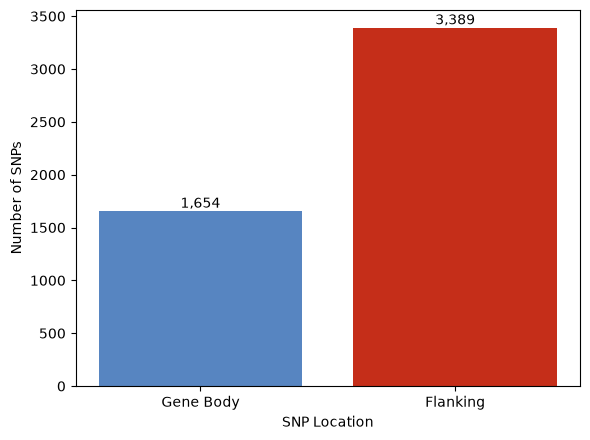

In [244]:
c = consolidated.copy()
c['top_term'] = c['top_consequence'].str.split(',').str[0]
order = [b for b in ['gene body', 'flanking', 'none'] if b in set(c['assignment_basis'])]
two = [b for b in ['gene body', 'flanking'] if b in order]
colors = {'gene body': '#5785C1', 'flanking': '#C52E19', 'none': '#D3D4D8'}

counts = c['assignment_basis'].value_counts().reindex(order)
labels = [k.title() for k in counts.index]

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(labels, counts.values, color=[colors[k] for k in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v + counts.max() * 0.01, f"{v:,}", ha='center')
ax.set_xlabel('SNP Location')
ax.set_ylabel('Number of SNPs')
plt.tight_layout()
plt.savefig(f'{out_dir}/assignment_basis.png', dpi=150, bbox_inches='tight')
plt.show()

### Plot Distance of Flanking SNPs from Gene

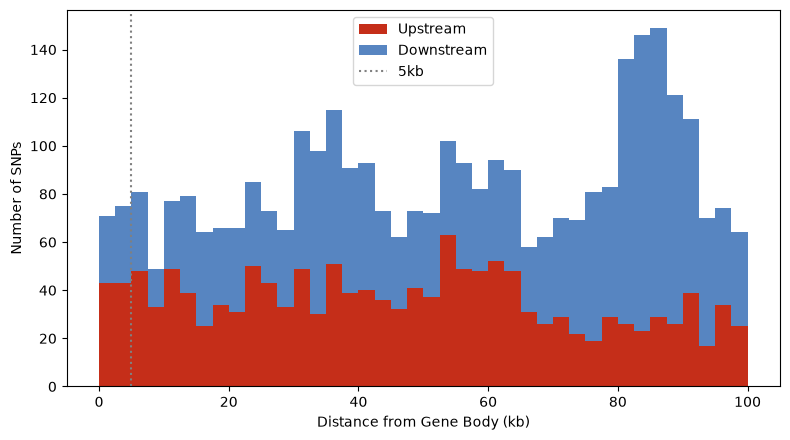

146 of 3,389 flanking SNPs are within 5 kb


In [245]:
f = c[c['assignment_basis'] == 'flanking']
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(0, window / 1000, 41)
ax.hist([f.loc[f['flank_side'] == s, 'epi_gene_distance'] / 1000 for s in ['upstream', 'downstream']],
        bins=bins, stacked=True, color=['#C52E19', '#5785C1'], label=['Upstream', 'Downstream'])
ax.axvline(5, color='grey', ls=':', label="5kb")
ax.set_xlabel('Distance from Gene Body (kb)')
ax.set_ylabel('Number of SNPs')
ax.legend()
plt.tight_layout()
plt.savefig(f'{out_dir}/flank_distance.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"{(f['epi_gene_distance'] <= 5000).sum():,} of {len(f):,} flanking SNPs are within 5 kb")

### Plot Genes in Each Stratum

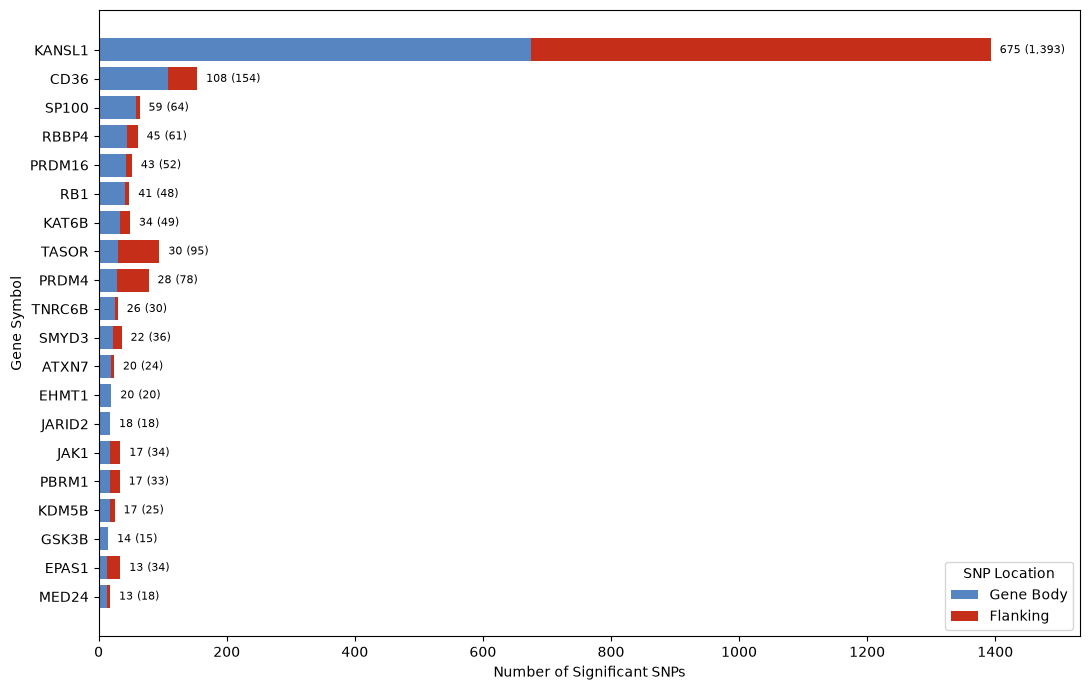

In [246]:
top_n = 20
sub = c[c['assignment_basis'].isin(['gene body', 'flanking'])]
tab = (sub.groupby(['epi_gene_final', 'assignment_basis']).size()
          .unstack(fill_value=0)
          .reindex(columns=['gene body', 'flanking'], fill_value=0))
tab['total'] = tab.sum(axis=1)
tab = tab.sort_values(['gene body', 'flanking'], ascending=False).head(top_n)

fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(tab))
ax.barh(y, tab['gene body'], color='#5785C1', label='Gene Body')
ax.barh(y, tab['flanking'], left=tab['gene body'], color='#C52E19', label='Flanking')
for i, (body, total) in enumerate(zip(tab['gene body'], tab['total'])):
    ax.text(total + tab['total'].max() * 0.01, i, f"{body:,} ({total:,})", va='center', fontsize=8)
ax.set_yticks(y, tab.index)
ax.invert_yaxis()
ax.set_xlabel('Number of Significant SNPs')
ax.set_ylabel('Gene Symbol')
ax.set_xlim(0, tab['total'].max() * 1.1)
ax.legend(title='SNP Location')
plt.tight_layout()
plt.savefig(f'{out_dir}/top_genes_stacked.png', dpi=150, bbox_inches='tight')
plt.show()



### Plot Consequence and Impact

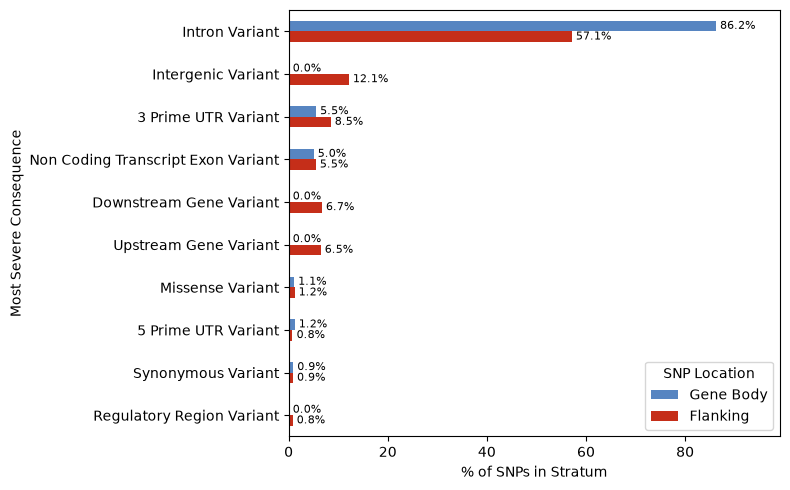

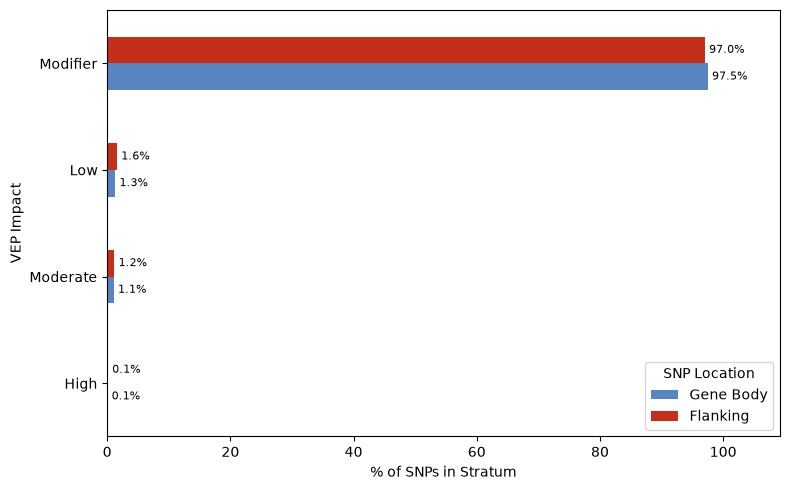

In [247]:
def pretty(s):
    s = str(s).replace('_', ' ').title()
    replacements = {'Utr': 'UTR', 'Nmd': 'NMD', 'Tfbs': 'TFBS', 'Tf ': 'TF ', 'Mirna': 'miRNA'}
    for raw, clean in replacements.items():
        s = s.replace(raw, clean)
    return s

sub = c[c['assignment_basis'].isin(two)]
top_terms = sub['top_term'].value_counts().head(10).index
st = sub[sub['top_term'].isin(top_terms)]

tab = (pd.crosstab(st['top_term'], st['assignment_basis'], normalize='columns') * 100).reindex(top_terms)[two]
imp = (pd.crosstab(sub['impact'], sub['assignment_basis'], normalize='columns') * 100)
imp = imp.reindex([i for i in ['HIGH', 'MODERATE', 'LOW', 'MODIFIER'] if i in imp.index])[two]

for d in (tab, imp):
    d.index = [pretty(i) for i in d.index]
    d.columns = [pretty(b) for b in d.columns]

bar_colors = ['#5785C1', '#C52E19']

fig1, ax1 = plt.subplots(figsize=(8, 5))  

tab.plot.barh(ax=ax1, color=bar_colors)
ax1.invert_yaxis()
ax1.set_xlabel('% of SNPs in Stratum')
ax1.set_ylabel('Most Severe Consequence')
ax1.set_xlim(0, tab.to_numpy().max() * 1.15)

for cont in ax1.containers:
    ax1.bar_label(cont, fmt='%.1f%%', padding=3, fontsize=8)

handles1, labels1 = ax1.get_legend_handles_labels()
ax1.legend(handles1, [lbl.title() for lbl in labels1], title='SNP Location')

plt.tight_layout()
plt.savefig(f'{out_dir}/consequence_by_stratum.png', dpi=150, bbox_inches='tight')
plt.show()

fig2, ax2 = plt.subplots(figsize=(8, 5))  

imp.plot.barh(ax=ax2, color=bar_colors, rot=0)
ax2.set_xlabel('% of SNPs in Stratum')
ax2.set_ylabel('VEP Impact')
ax2.set_xlim(0, imp.to_numpy().max() * 1.12)

for cont in ax2.containers:
    ax2.bar_label(cont, fmt='%.1f%%', padding=3, fontsize=8)

handles2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(handles2, [lbl.title() for lbl in labels2], title='SNP Location')

plt.tight_layout()
plt.savefig(f'{out_dir}/impact_by_stratum.png', dpi=150, bbox_inches='tight')
plt.show()

### Plot Top SNPs

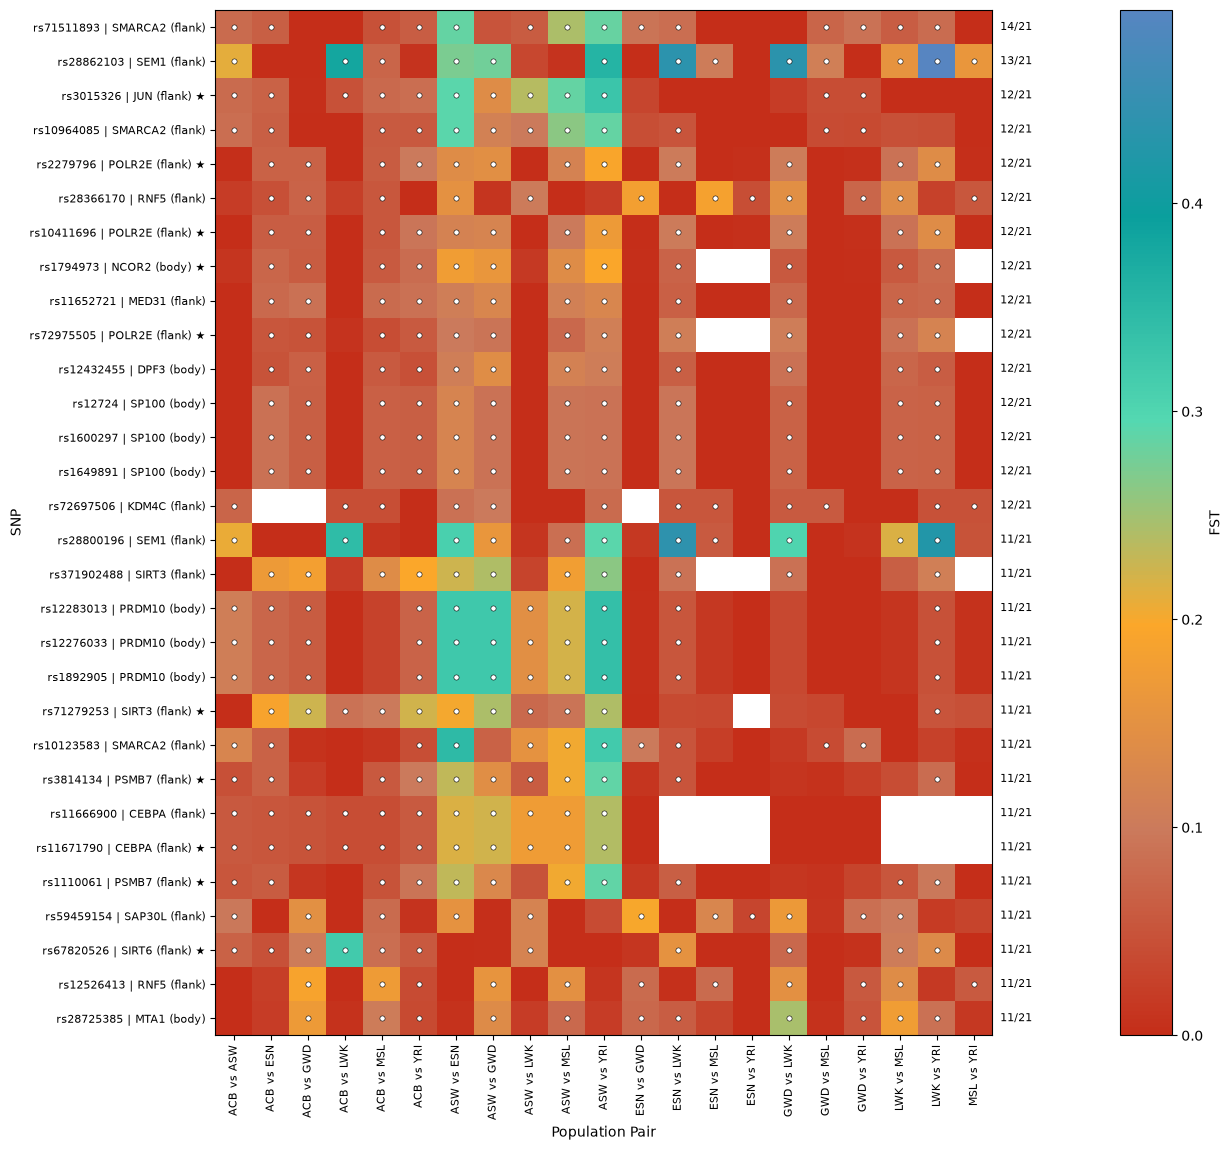

In [248]:
top_snps = 30
max_per_gene = 3        

d = final.copy()
d['_sig'] = d['significantly_differentiated'].astype(bool)
d['pair'] = d['pop_a'] + ' vs ' + d['pop_b']

rank = (d.groupby('CHROM_POS')
          .agg(n_sig_pairs=('_sig', 'sum'), max_fst=('fst', 'max'), min_p_adj=('p_adj_BH', 'min')))
rank['mean_fst_sig'] = d[d['_sig']].groupby('CHROM_POS')['fst'].mean()
rank = rank.fillna({'mean_fst_sig': 0}).reset_index()

info = (consolidated[['snp_key', 'epi_gene_final', 'assignment_basis', 'has_gwas_hit', 'has_clinvar_hit']]
        .drop_duplicates('snp_key').rename(columns={'snp_key': 'CHROM_POS'}))
rank = rank.merge(info, on='CHROM_POS', how='left')
rank = rank.sort_values(['n_sig_pairs', 'mean_fst_sig'], ascending=False)
if max_per_gene:
    rank = rank.groupby(rank['epi_gene_final'].fillna(rank['CHROM_POS']), sort=False).head(max_per_gene)
top = rank.head(top_snps).reset_index(drop=True)
top['rsid'] = top['CHROM_POS'].map(rsid_all)
top.to_csv(f'{out_dir}/top_significant_snps.csv', index=False)

pairs = [f"{a} vs {b}" for a, b in combinations(populations, 2)]
fst_m = d[d['CHROM_POS'].isin(top['CHROM_POS'])].pivot(index='CHROM_POS', columns='pair', values='fst').reindex(top['CHROM_POS'])[pairs]
sig_m = d[d['CHROM_POS'].isin(top['CHROM_POS'])].pivot(index='CHROM_POS', columns='pair', values='_sig').reindex(top['CHROM_POS'])[pairs]

def row_label(r):
    snp = rsid_of.get(r['CHROM_POS'], r['CHROM_POS'])               # rsID if known, otherwise the coordinate
    where = {'gene body': 'body', 'flanking': 'flank'}.get(r['assignment_basis'], '')
    gene = f" | {r['epi_gene_final']} ({where})" if pd.notna(r['epi_gene_final']) else ''
    star = ' ★' if (r['has_gwas_hit'] == True or r['has_clinvar_hit'] == True) else ''
    return f"{snp}{gene}{star}"

custom_cmap = sns.blend_palette(
    ["#C52E19", "#CB7A5C", "#FBA72A", "#54D8B1", "#0A9F9D", "#5785C1"], as_cmap=True
)

fig, ax = plt.subplots(figsize=(13, max(5, 0.32 * len(top) + 2)))
im = ax.imshow(fst_m.to_numpy(float), aspect='auto', cmap=custom_cmap, vmin=0)
ys, xs = np.where(sig_m.to_numpy(dtype=bool))
ax.scatter(xs, ys, s=14, color='white', edgecolor='black', linewidth=0.4)
ax.set_yticks(range(len(top)), [row_label(r) for _, r in top.iterrows()], fontsize=8)
ax.set_xticks(range(len(pairs)), pairs, rotation=90, fontsize=8)
for i, n in enumerate(top['n_sig_pairs']):
    ax.text(len(pairs) - 0.4, i, f" {int(n)}/{len(pairs)}", va='center', fontsize=8)
ax.set_xlim(-0.5, len(pairs) - 0.5)
ax.set_xlabel('Population Pair')
ax.set_ylabel('SNP')
plt.colorbar(im, ax=ax, label='FST', pad=0.12)
plt.tight_layout()
plt.savefig(f'{out_dir}/top_significant_snps.png', dpi=150, bbox_inches='tight')
plt.show()

# Analysis of Co-occurrence of Variants
---
### Extract Genotypes

In [249]:
%%bash

pops=(ACB ASW ESN GWD LWK MSL YRI)

for pop in "${pops[@]}"; do
    bcftools view -R ../data/cooccurrence_analysis/sig_snps.bed \
                  -S ../data/population_data/${pop}/${pop}_samples_clean.txt \
                  ../data/population_data/${pop}/${pop}_epi_highfreq_clean.vcf.gz \
                  -Oz -o ../data/cooccurrence_analysis/${pop}/${pop}_sig_genotypes.vcf.gz
    
    bcftools query -f '%CHROM:%POS[\t%GT]\n' \
                    ../data/cooccurrence_analysis/${pop}/${pop}_sig_genotypes.vcf.gz \
                    > ../data/cooccurrence_analysis/${pop}/${pop}_genotype_matrix.tsv
    
    bcftools query -l ../data/cooccurrence_analysis/${pop}/${pop}_sig_genotypes.vcf.gz \
                    > ../data/cooccurrence_analysis/${pop}/${pop}_sample_order.txt
    
    echo "${pop}: done"
done

ACB: done
ASW: done
ESN: done
GWD: done
LWK: done
MSL: done
YRI: done


### Load Genotypes and Set Up

In [250]:
out_dir = '../data/cooccurrence_analysis'

def load_genotypes(pop):
    """int8 matrix (SNPs x samples): 1 = carrier of the alt allele, 0 = non-carrier, -1 = missing."""
    samples = pd.read_csv(f'{out_dir}/{pop}/{pop}_sample_order.txt', header=None)[0].tolist()
    gt = pd.read_csv(f'{out_dir}/{pop}/{pop}_genotype_matrix.tsv', sep='\t', header=None,
                     names=['snp_key'] + samples, dtype=str, index_col=0)
    gt = gt[~gt.index.duplicated()]                     
    cols = []
    for s in samples:
        col = gt[s].fillna('.')
        missing = col.str.contains('.', regex=False)
        carrier = col.str.replace(r'[|/0]', '', regex=True).str.len() > 0
        cols.append(np.where(missing, -1, np.where(carrier, 1, 0)).astype(np.int8))
    return pd.DataFrame(np.column_stack(cols), index=gt.index, columns=samples)

P_SIG = 0.05

genotypes = {pop: load_genotypes(pop) for pop in populations}
snp_order = sorted(set.intersection(*[set(g.index) for g in genotypes.values()]))
snp_idx = {k: i for i, k in enumerate(snp_order)}
M = len(snp_order)
geno = {pop: g.loc[snp_order].to_numpy() for pop, g in genotypes.items()}    
snp_chrom = np.array([k.split(':')[0].replace('chr', '') for k in snp_order])
snp_pos = np.array([int(k.split(':')[1]) for k in snp_order])

sg = pd.read_csv('../data/gene_annotation/snp_gene_membership.csv')
sg = sg[sg['snp_key'].isin(snp_idx)].copy()
sg['gene'] = sg['gene'].str.upper()
sg['i'] = sg['snp_key'].map(snp_idx)

def snps_by_gene(relations):
    """gene -> sorted array of SNP indices whose relation to the gene is in `relations`"""
    t = sg[sg['relation'].isin(relations)]
    return {g: np.unique(v.to_numpy()) for g, v in t.groupby('gene')['i']}

TYPE_NAMES = {0: 'same gene', 1: 'same chromosome', 2: 'different chromosomes'}
print(f"{M:,} SNPs | {', '.join(f'{p}: {geno[p].shape[1]} samples' for p in populations)}")

5,043 SNPs | ACB: 112 samples, ASW: 67 samples, ESN: 149 samples, GWD: 178 samples, LWK: 99 samples, MSL: 99 samples, YRI: 178 samples


### Test Functions

In [251]:
def family_keys(sets, M):
    chunks, total = [], 0
    for members in sets.values():
        members = np.unique(members)
        ia, ib = np.triu_indices(len(members), 1)
        chunks.append(members[ia].astype(np.int64) * M + members[ib])
        total += len(chunks[-1])
        if total > 20_000_000:
            chunks = [np.unique(np.concatenate(chunks))]
            total = len(chunks[0])
    return np.unique(np.concatenate(chunks)) if chunks else np.empty(0, np.int64)

def cooccurrence_counts(G, ia, ib, chunk=100_000):
    out = np.zeros((len(ia), 4), dtype=np.int16)
    for s in range(0, len(ia), chunk):
        A, B = G[ia[s:s + chunk]], G[ib[s:s + chunk]]
        a1, a0, b1, b0 = (A == 1), (A == 0), (B == 1), (B == 0)
        out[s:s + chunk, 0] = (a1 & b1).sum(1)
        out[s:s + chunk, 1] = (a1 & b0).sum(1)
        out[s:s + chunk, 2] = (a0 & b1).sum(1)
        out[s:s + chunk, 3] = (a0 & b0).sum(1)
    return out

def test_population(G, ia, ib):
    cnt = cooccurrence_counts(G, ia, ib)
    both, only_a, only_b, neither = [cnt[:, k].astype(np.int32) for k in range(4)]
    informative = (((both + only_a) > 0) & ((only_b + neither) > 0) &
                   ((both + only_b) > 0) & ((only_a + neither) > 0))
    b, oa, ob, nn = [x.astype(np.uint32) for x in (both, only_a, only_b, neither)]
    _, p_right, _ = fisher.pvalue_npy(b, oa, ob, nn)
    odds = ((b + .5) * (nn + .5)) / ((oa + .5) * (ob + .5))
    return dict(counts=cnt, p=np.asarray(p_right), log2_or=np.log2(odds).astype(np.float32), ok=informative)

def family_bh(idx, res):
    ok = res['ok'][idx]
    p_adj = np.full(len(idx), np.nan, dtype=np.float32)
    if ok.any():
        p_adj[ok] = multipletests(res['p'][idx][ok], method='fdr_bh')[1]
    return p_adj

def summarise_family(fam, sets, M, fam_keys, fam_idx, fam_padj, pop_res, type_code, set_ngenes=None):
    fk, fidx = fam_keys[fam], fam_idx[fam]
    rows = []
    for name, members in sets.items():
        members = np.unique(members)
        i, j = np.triu_indices(len(members), 1)
        pos_f = np.searchsorted(fk, members[i].astype(np.int64) * M + members[j])
        u = fidx[pos_f]                        
        cross = type_code[u] == 2
        for pop, res in pop_res.items():
            padj = fam_padj[(fam, pop)][pos_f]
            ok = ~np.isnan(padj)
            if not ok.any():
                continue
            sig = ok & (padj < 0.05)
            rows.append(dict(
                family=fam, set=name, population=pop, n_snps=len(members),
                n_genes=(set_ngenes or {}).get(name, 1),
                n_pairs_tested=int(ok.sum()), n_sig=int(sig.sum()),
                pct_sig=100 * sig.sum() / ok.sum(),
                n_tested_cross_chrom=int((ok & cross).sum()),
                n_sig_cross_chrom=int((sig & cross).sum()),
                median_log2_or_sig=float(np.median(res['log2_or'][u][sig])) if sig.any() else np.nan))
    return pd.DataFrame(rows)

def significant_pairs(families, fam_idx, fam_padj, pop_res, populations, ia, ib, snp_order, type_code, dist_kb,
                      TYPE_NAMES, snp_gene_of):
    names = np.array(snp_order)
    out = []
    for fam in families:
        for pop in populations:
            padj = fam_padj[(fam, pop)]
            s = np.where(padj < 0.05)[0]
            if len(s) == 0:
                continue
            u, r = fam_idx[fam][s], pop_res[pop]
            a, b = names[ia[u]], names[ib[u]]
            out.append(pd.DataFrame({
                'family': fam, 'population': pop, 'snp_a': a, 'snp_b': b,
                'gene_a': pd.Series(a).map(snp_gene_of).to_numpy(),
                'gene_b': pd.Series(b).map(snp_gene_of).to_numpy(),
                'pair_type': pd.Series(type_code[u]).map(TYPE_NAMES).to_numpy(), 'distance_kb': dist_kb[u],
                'both': r['counts'][u, 0], 'only_a': r['counts'][u, 1],
                'only_b': r['counts'][u, 2], 'neither': r['counts'][u, 3],
                'p_value': r['p'][u], 'p_adj_BH': padj[s], 'log2_or': r['log2_or'][u]}))
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()

def inflation_lambda(p):
    chi2 = stats.chi2.isf(np.clip(p, 1e-300, 1), 1)
    return float(np.median(chi2) / stats.chi2.ppf(0.5, 1))

### Define Genes and Pathway Sets

In [252]:
GENE_FAMILIES = {'gene: body': {'body'},          
                 'gene: body+flank': {'body', 'flank'}} 

PATHWAY_SOURCE = 'reactome'   
PATHWAY_RELATIONS = {'body', 'flank'}
MIN_GENES_PER_PATHWAY = 2
MAX_SNPS_PER_SET = 2000 
MAX_UNION_PAIRS = 25_000_000

def parse_gmt_lines(lines):
    sets = {}
    for line in lines:
        f = line.rstrip('\n').split('\t')
        genes = f[2:] if len(f) > 2 and f[1].startswith('R-') else f[1:]
        sets[f[0]] = {g.upper() for g in genes if g}
    return sets

def load_pathways():
    if PATHWAY_SOURCE == 'reactome':
        with open('../data/reference_data/ReactomePathways.gmt') as f: 
            return parse_gmt_lines(f)

fam_sets, set_ngenes = {}, {}
for fam, rel in GENE_FAMILIES.items():
    fam_sets[fam] = {g: v for g, v in snps_by_gene(rel).items() if len(v) >= 2}
    set_ngenes.update({g: 1 for g in fam_sets[fam]})

by_gene = snps_by_gene(PATHWAY_RELATIONS)
pathways = load_pathways()
pw_sets, skipped_big = {}, 0
for name, genes in pathways.items():
    hit = [g for g in genes if g in by_gene]
    if len(hit) < MIN_GENES_PER_PATHWAY:
        continue
    snps = np.unique(np.concatenate([by_gene[g] for g in hit]))
    if len(snps) > MAX_SNPS_PER_SET:
        skipped_big += 1
        continue
    pw_sets[name] = snps
    set_ngenes[name] = len(hit)
fam_sets['pathway'] = pw_sets

print(f"{len(pathways):,} pathways loaded -> {len(pw_sets):,} usable "
      f"(>= {MIN_GENES_PER_PATHWAY} genes with SNPs; {skipped_big} skipped as > {MAX_SNPS_PER_SET} SNPs)")
for fam, s in fam_sets.items():
    print(f"  {fam}: {len(s):,} sets")

2,868 pathways loaded -> 911 usable (>= 2 genes with SNPs; 7 skipped as > 2000 SNPs)
  gene: body: 99 sets
  gene: body+flank: 281 sets
  pathway: 911 sets


### Run Tests

In [253]:
families = list(fam_sets)
fam_keys = {fam: family_keys(s, M) for fam, s in fam_sets.items()}
for fam, k in fam_keys.items():
    print(f"{fam}: {len(k):,} SNP pairs")

union = np.unique(np.concatenate([k for k in fam_keys.values() if len(k)]))
assert len(union) <= MAX_UNION_PAIRS, f"{len(union):,} pairs; raise MAX_UNION_PAIRS or lower MAX_SNPS_PER_SET"
ia, ib = (union // M).astype(np.int64), (union % M).astype(np.int64)
print(f"Union of all families: {len(union):,} unique SNP pairs")

same_gene = np.isin(union, family_keys(snps_by_gene({'body', 'flank'}), M))
same_chr = snp_chrom[ia] == snp_chrom[ib]
type_code = np.where(same_gene, 0, np.where(same_chr, 1, 2)).astype(np.int8)
dist_kb = np.where(same_chr, np.abs(snp_pos[ia] - snp_pos[ib]) / 1000, np.nan).astype(np.float32)
print(pd.Series(type_code).map(TYPE_NAMES).value_counts().to_string())

pop_res = {}
for pop in populations:
    t0 = time.time()
    pop_res[pop] = test_population(geno[pop], ia, ib)
    print(f"{pop}: {pop_res[pop]['ok'].sum():,} informative of {len(union):,} pairs ({time.time() - t0:.0f}s)")

fam_idx = {fam: np.searchsorted(union, k) for fam, k in fam_keys.items()}
fam_padj = {(fam, pop): family_bh(fam_idx[fam], pop_res[pop]) for fam in families for pop in populations}

gene: body: 241,632 SNP pairs
gene: body+flank: 1,137,560 SNP pairs
pathway: 4,227,326 SNP pairs
Union of all families: 4,228,481 unique SNP pairs
different chromosomes    2914886
same gene                1137560
same chromosome           176035
ACB: 3,647,542 informative of 4,228,481 pairs (2s)
ASW: 3,950,472 informative of 4,228,481 pairs (1s)
ESN: 1,410,082 informative of 4,228,481 pairs (1s)
GWD: 3,105,211 informative of 4,228,481 pairs (2s)
LWK: 3,114,827 informative of 4,228,481 pairs (1s)
MSL: 1,340,111 informative of 4,228,481 pairs (1s)
YRI: 1,421,176 informative of 4,228,481 pairs (1s)


### Summary of Significant Pairs

In [254]:
set_summary = pd.concat([summarise_family(fam, fam_sets[fam], M, fam_keys, fam_idx, fam_padj,
                                          pop_res, type_code, set_ngenes) for fam in families],
                        ignore_index=True)
set_summary.to_csv(f'{out_dir}/cooccurrence_set_summary.csv', index=False)

rows = []
for fam in families:
    for pop in populations:
        padj = fam_padj[(fam, pop)]
        ok = ~np.isnan(padj)
        rows.append({'family': fam, 'population': pop, 'pairs_tested': int(ok.sum()),
                     'pairs_sig': int((padj[ok] < P_SIG).sum()),
                     'pct_sig': 100 * (padj[ok] < P_SIG).mean() if ok.any() else np.nan})
family_summary = pd.DataFrame(rows)
family_summary.to_csv(f'{out_dir}/cooccurrence_family_summary.csv', index=False)
display(family_summary.pivot(index='population', columns='family', values='pct_sig').round(2))

sig_pairs = significant_pairs(families, fam_idx, fam_padj, pop_res, populations, ia, ib, snp_order,
                              type_code, dist_kb, TYPE_NAMES,
                              consolidated.set_index('snp_key')['epi_gene_final'].to_dict())
sig_pairs.to_csv(f'{out_dir}/significant_cooccurring_pairs.csv', index=False)
print(f"{len(sig_pairs):,} significant (family, population, pair) rows")
print(sig_pairs.groupby(['family', 'pair_type']).size().unstack(fill_value=0))

for pop in populations:
    idx = fam_idx['pathway']
    m = (type_code[idx] == 2) & pop_res[pop]['ok'][idx]
    if m.any():
        print(f"{pop}: lambda = {inflation_lambda(pop_res[pop]['p'][idx][m]):.2f} "
              f"({m.sum():,} different-chromosome pathway pairs)")

family,gene: body,gene: body+flank,pathway
population,,,
ACB,97.60,95.61,30.15
ASW,97.74,95.76,27.93
ESN,69.92,81.05,8.99
GWD,97.69,95.37,34.54
LWK,97.39,94.85,20.38
MSL,48.52,74.59,7.85
YRI,77.53,76.38,7.69


9,853,485 significant (family, population, pair) rows
pair_type         different chromosomes  same chromosome  same gene
family                                                             
gene: body                            0                0     955288
gene: body+flank                      0                0    4648012
pathway                           57232            11305    4181648
ACB: lambda = 0.31 (2,373,961 different-chromosome pathway pairs)
ASW: lambda = 0.32 (2,658,187 different-chromosome pathway pairs)
ESN: lambda = 0.10 (1,170,057 different-chromosome pathway pairs)
GWD: lambda = 0.02 (1,883,810 different-chromosome pathway pairs)
LWK: lambda = 0.07 (1,899,439 different-chromosome pathway pairs)
MSL: lambda = 0.14 (1,114,628 different-chromosome pathway pairs)
YRI: lambda = 0.11 (1,180,852 different-chromosome pathway pairs)


### Plot % Of Significant Pairs

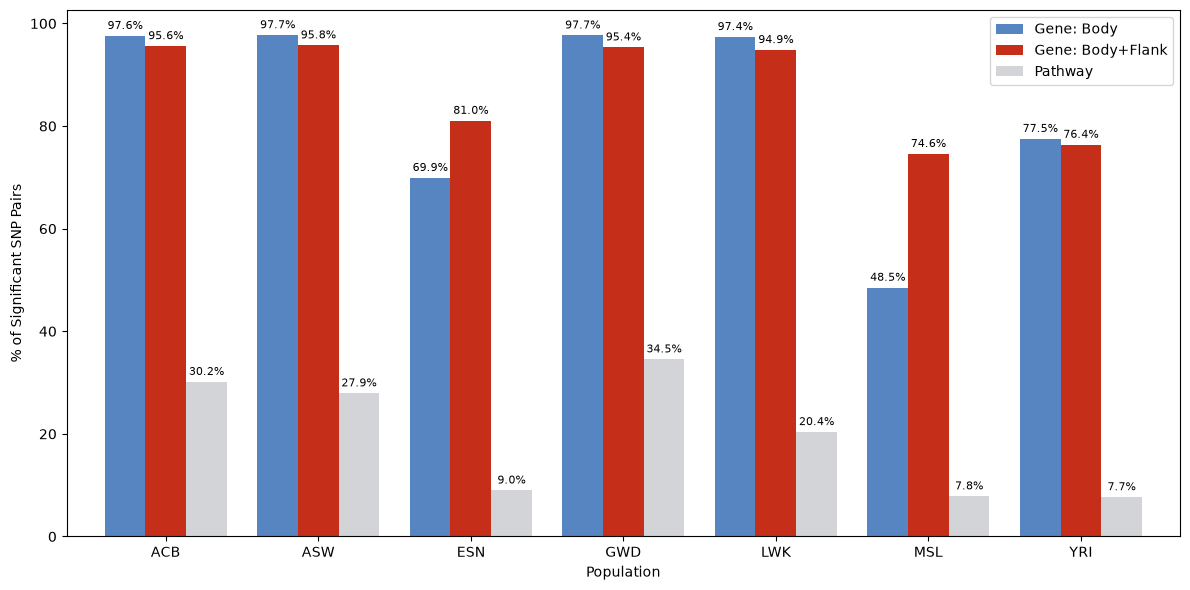

In [255]:
fam_colors = {'gene: body': '#5785C1', 'gene: body+flank': '#C52E19', 'pathway': '#D3D4D8'}

pv = family_summary.pivot(index='population', columns='family', values='pct_sig').reindex(populations)[families]
ax = pv.plot.bar(figsize=(12, 6), color=[fam_colors[f] for f in pv.columns], rot=0, width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=8)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [label.title() for label in labels])
ax.set_xlabel('Population')
ax.set_ylabel('% of Significant SNP Pairs')
plt.tight_layout()
plt.savefig(f'{out_dir}/cooccurrence_pct_sig_by_family.png', dpi=150, bbox_inches='tight')
plt.show()

### Plot Top Genes and Pathways

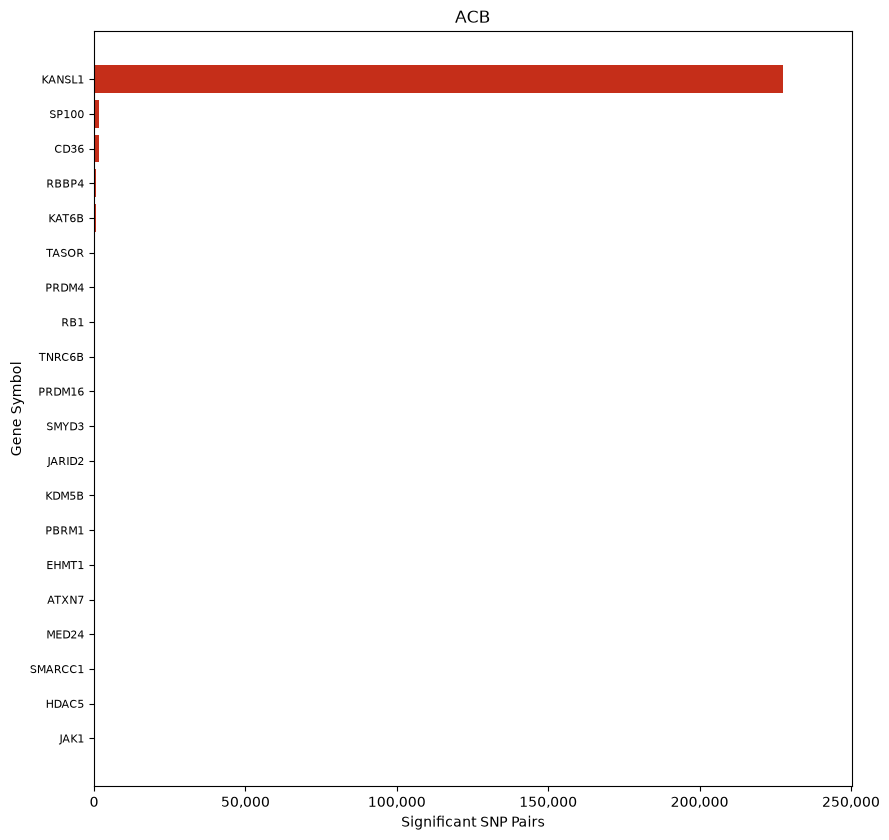

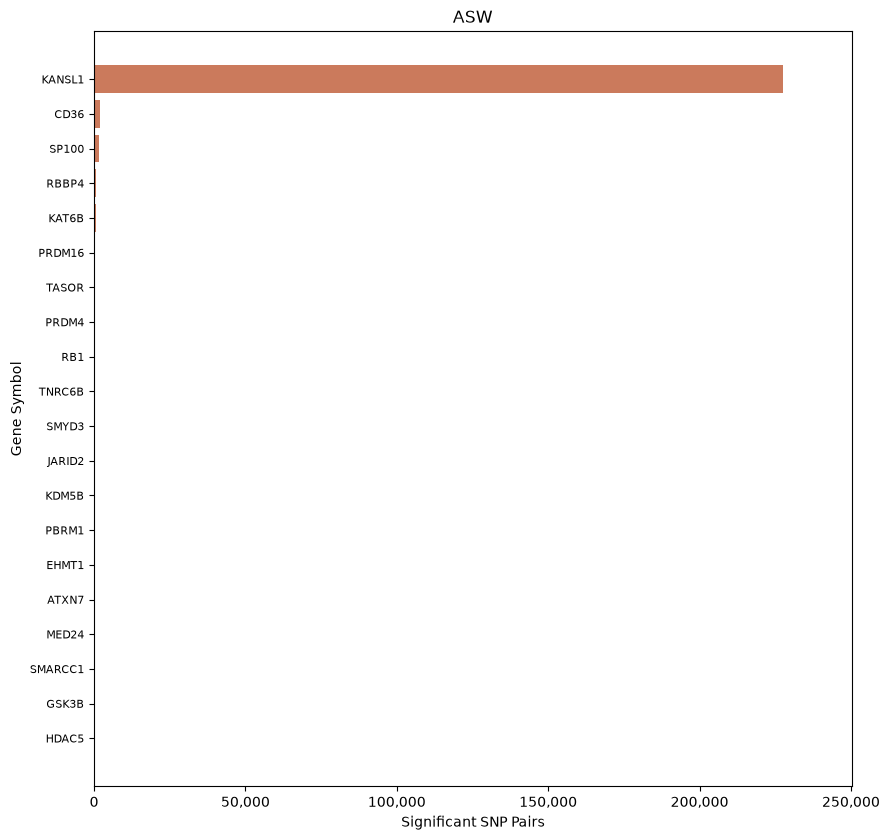

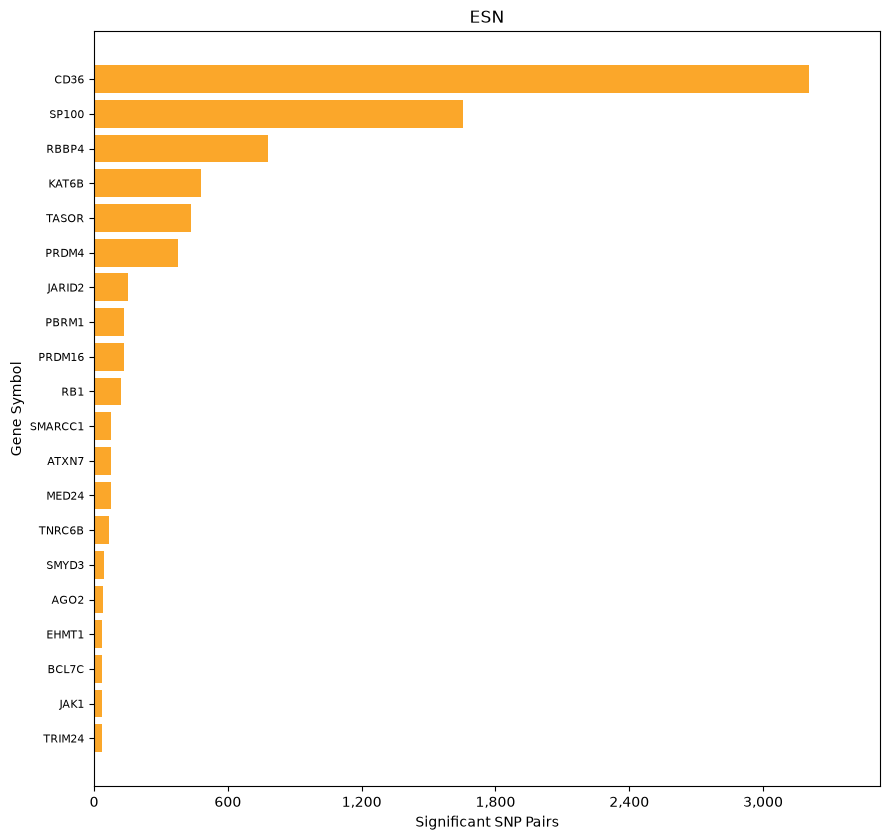

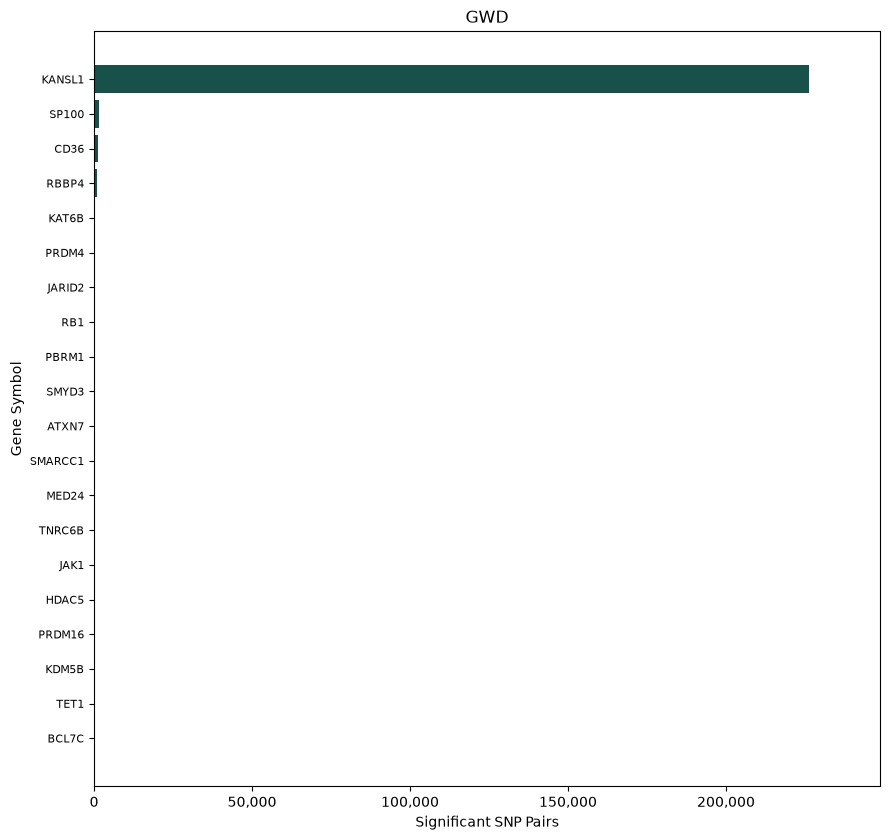

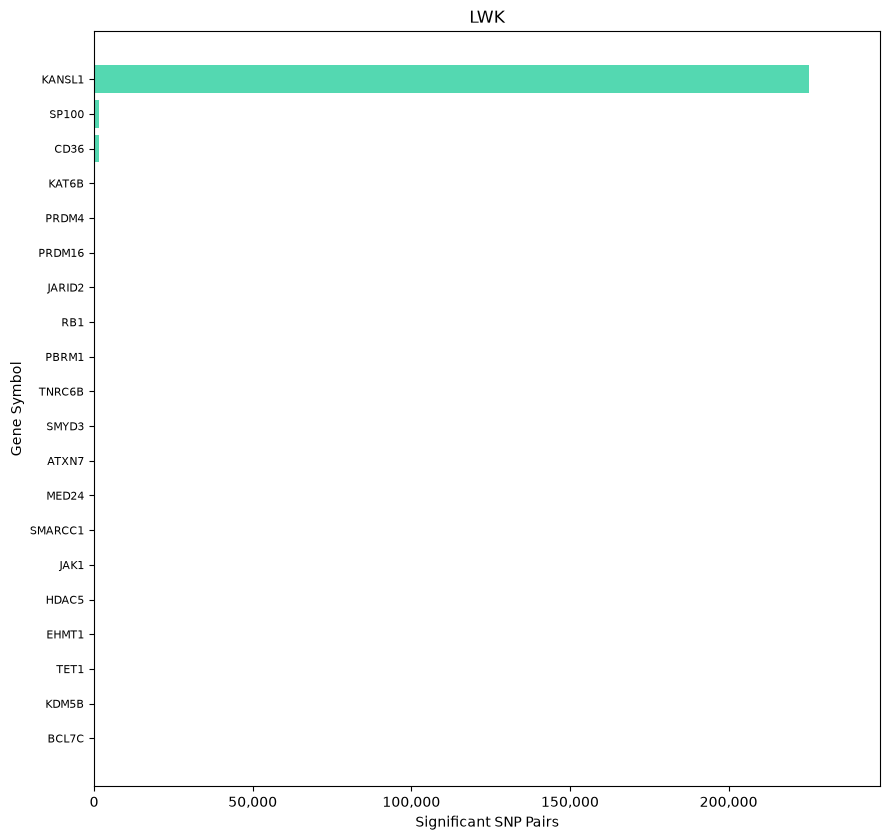

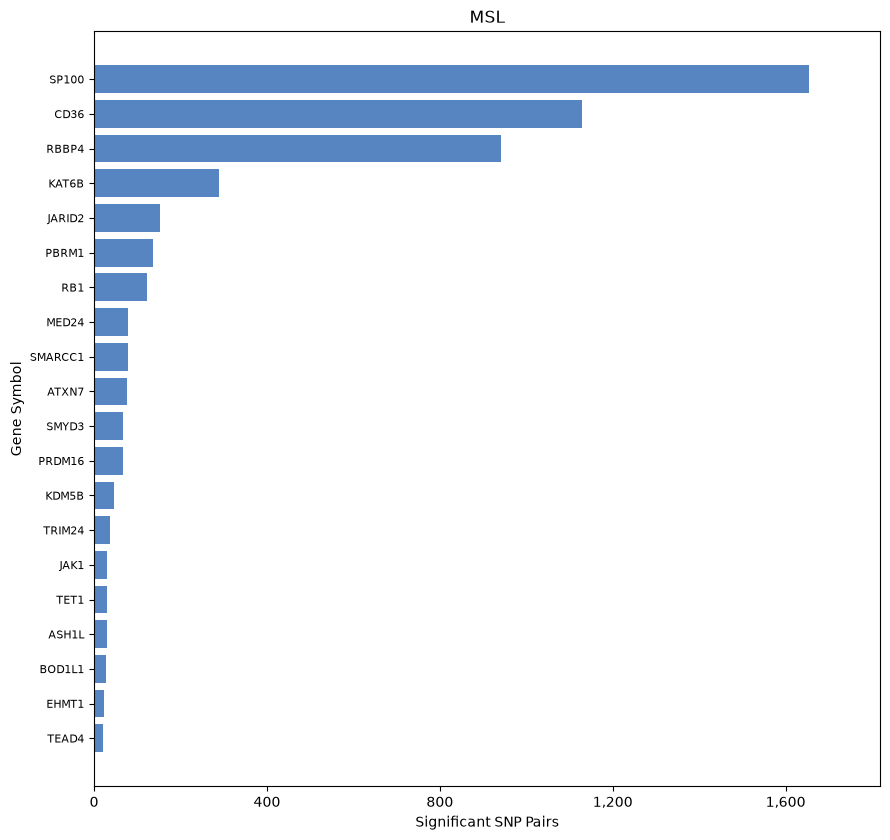

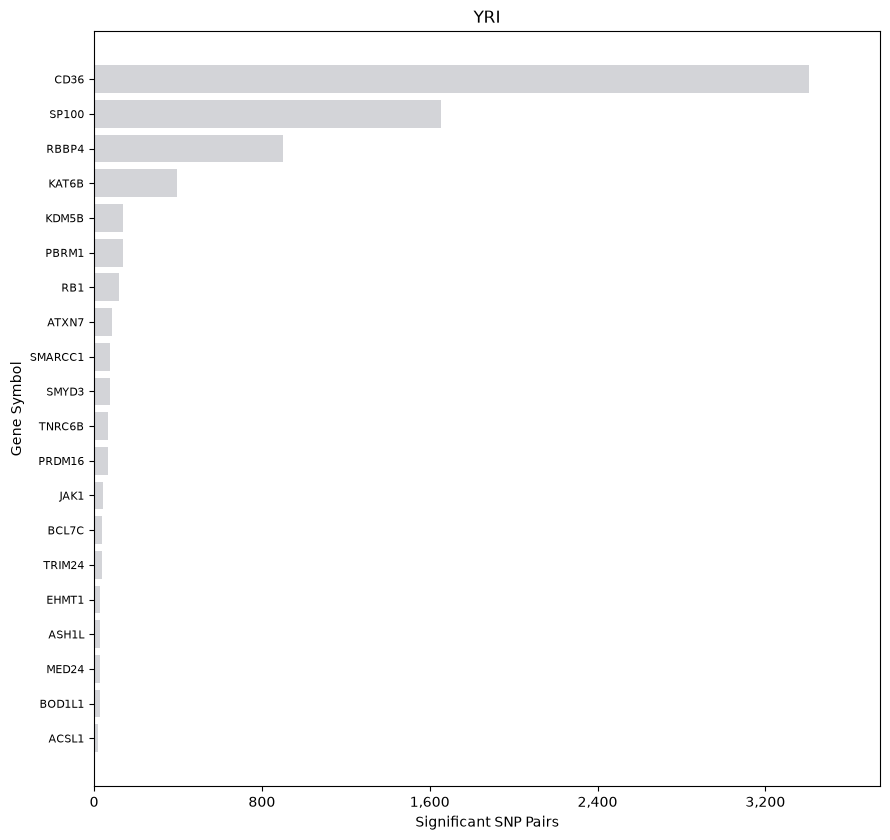

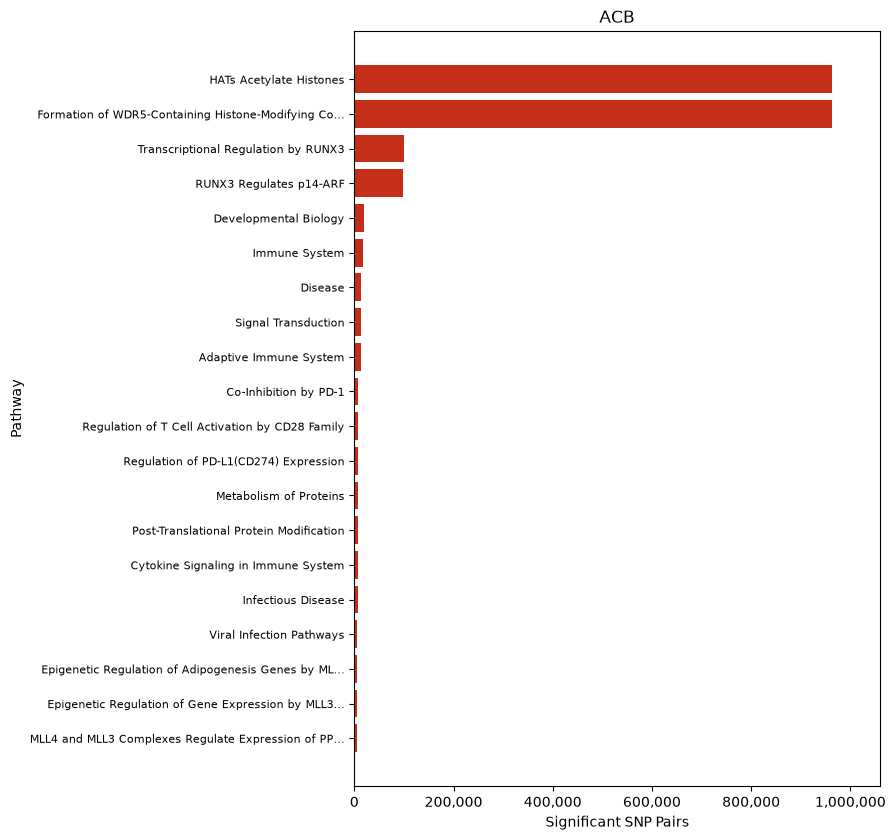

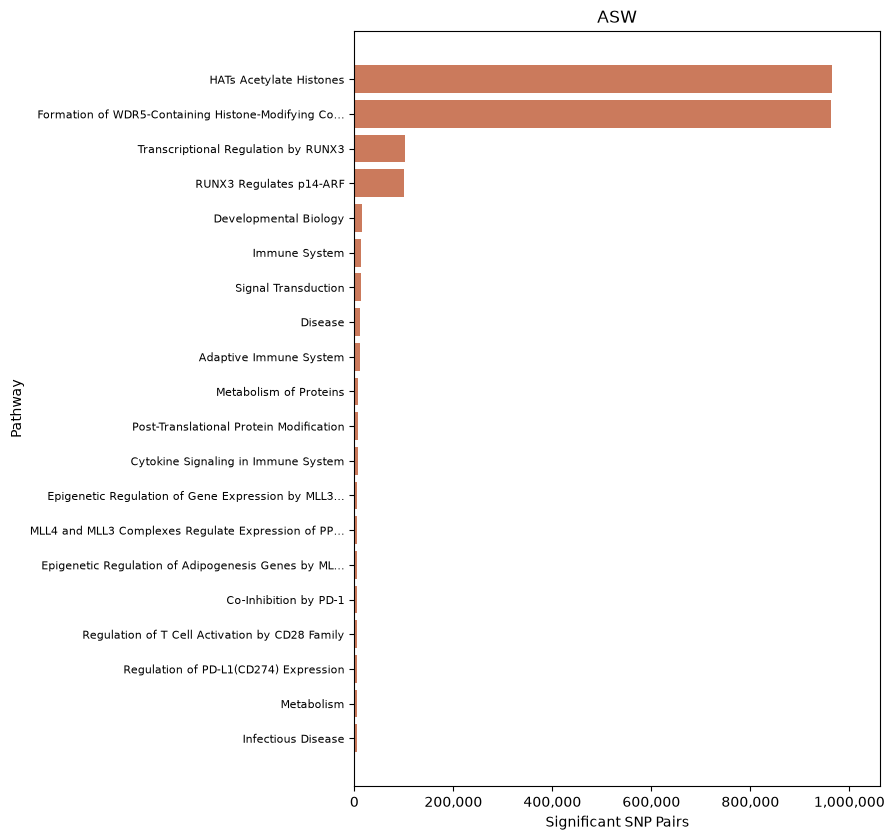

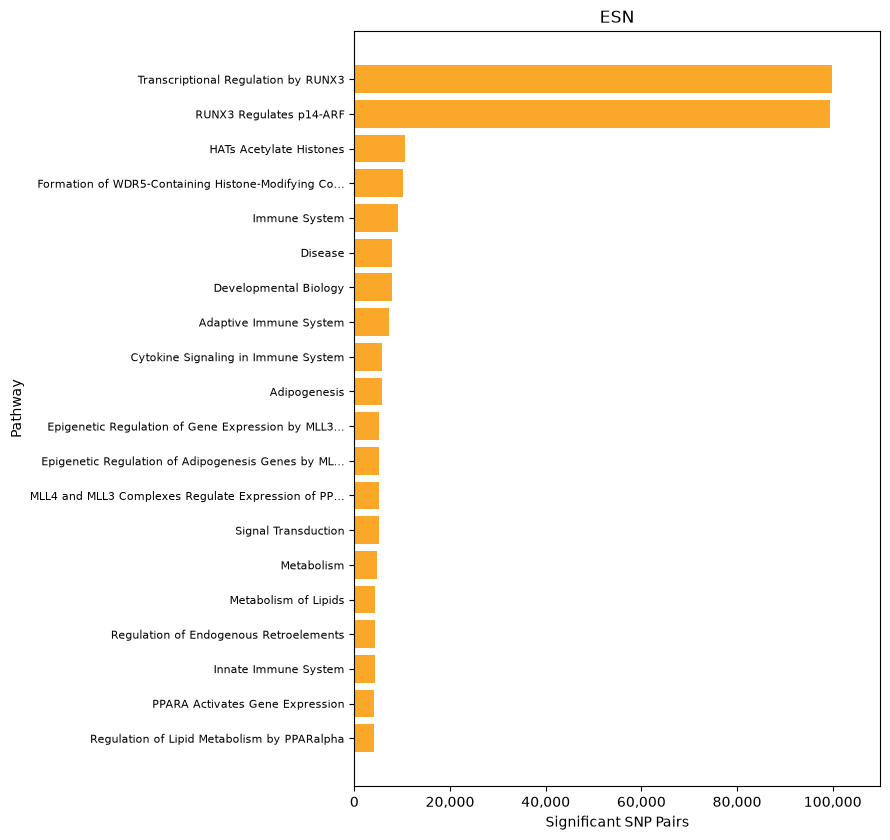

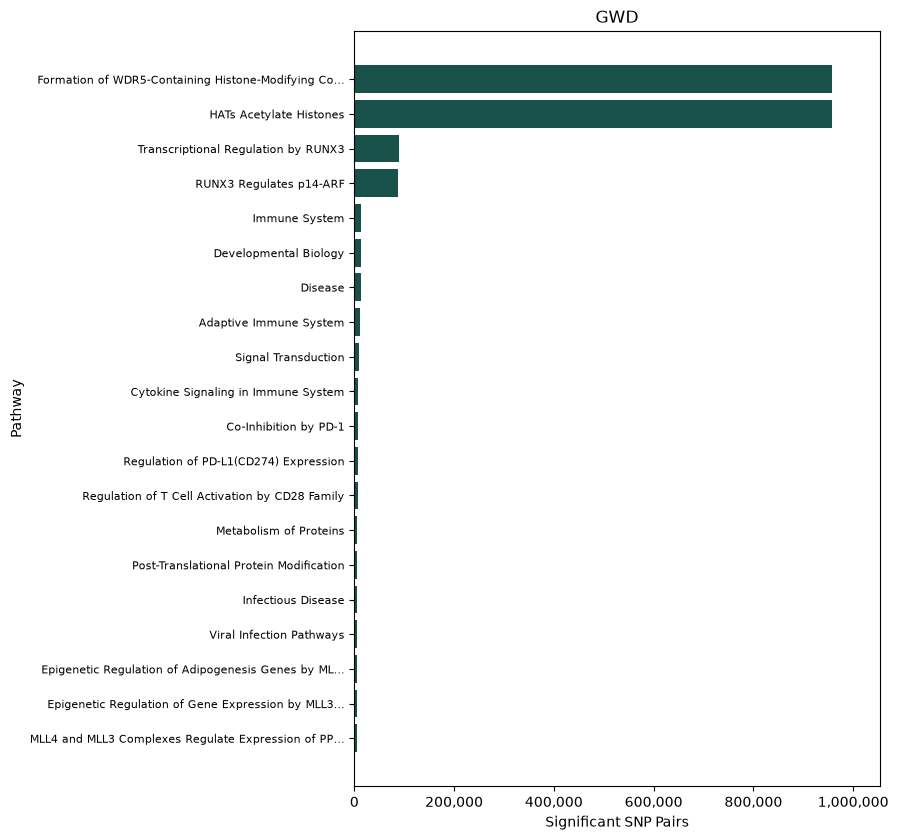

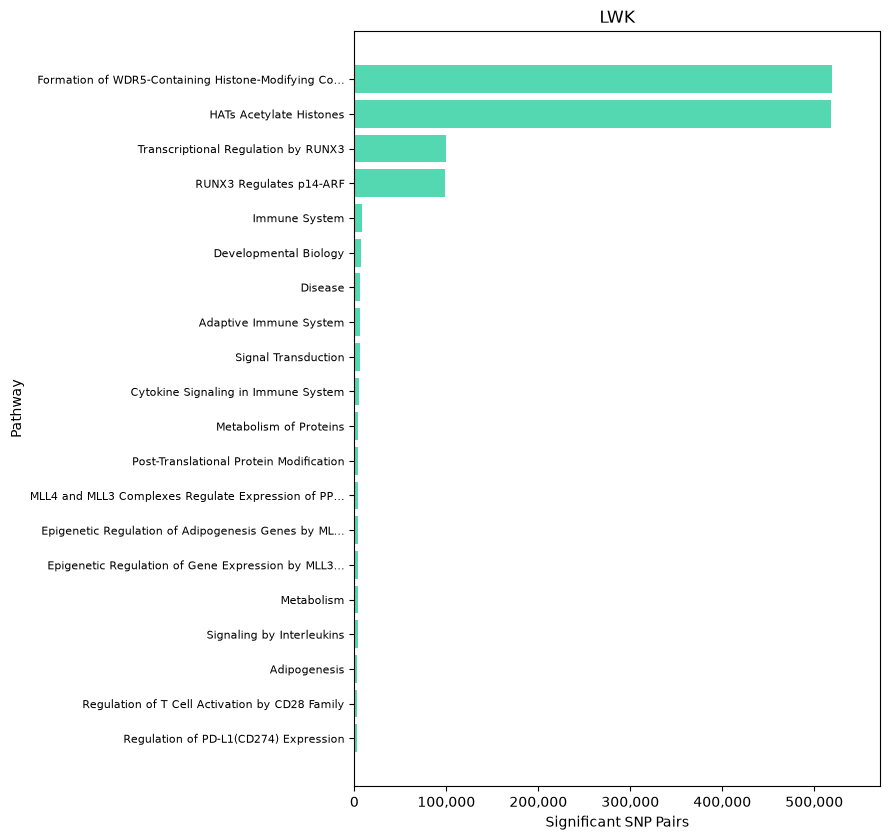

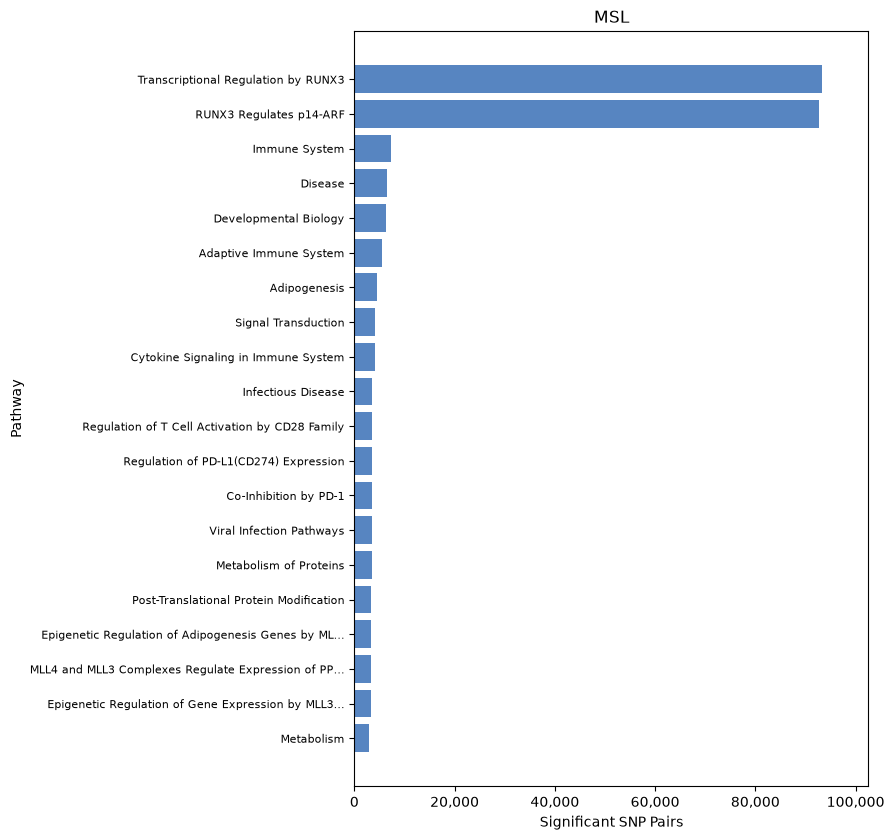

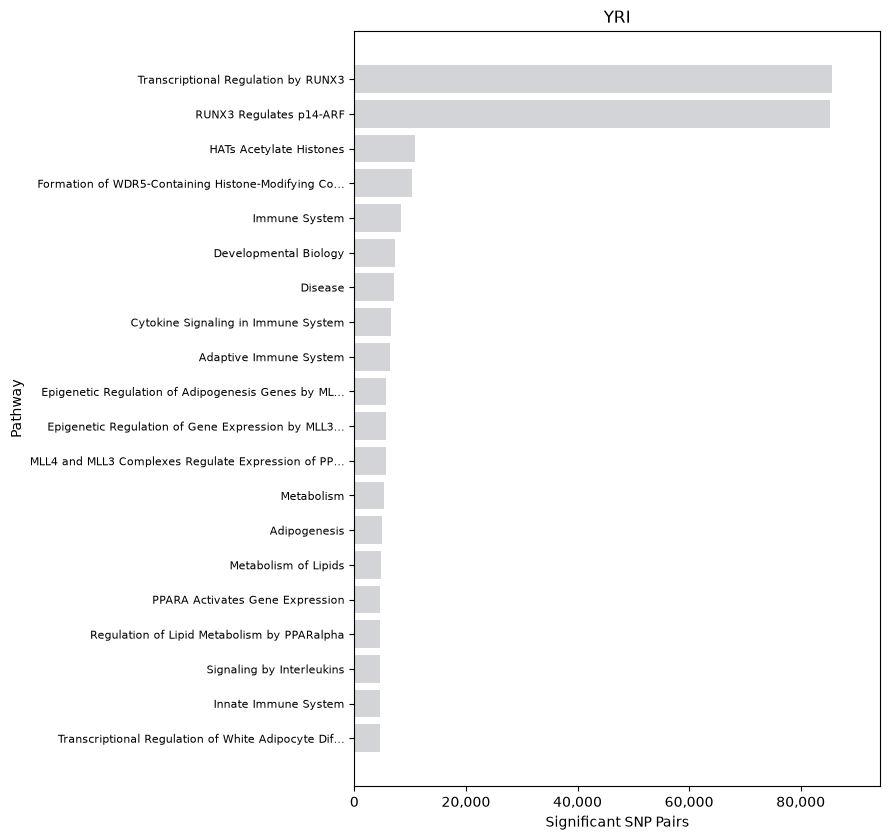

In [256]:
top_n = 20
min_sig = 1
colors = ["#C52E19", "#CB7A5C", "#FBA72A", "#175149", "#54D8B1", "#5785C1", "#D3D4D8"]

SMALL_WORDS = {'a', 'an', 'and', 'as', 'at', 'by', 'for', 'from', 'in', 'of', 'on', 'or', 'the', 'to', 'via', 'with', 'vs'}

def _title_part(w, first):
    if any(ch.isdigit() for ch in w) or any(ch.isupper() for ch in w[1:]):
        return w                           
    if w.lower() in SMALL_WORDS and not first:
        return w.lower()
    return w[:1].upper() + w[1:]

def smart_title(s):
    out = []
    for i, word in enumerate(str(s).split(' ')):
        out.append('-'.join(_title_part(p, i == 0 and j == 0) for j, p in enumerate(word.split('-'))))
    return ' '.join(out)

def shorten(s, n):
    return s if len(s) <= n else s[:n - 1].rstrip() + '…'

def top_sets(family, top_n=top_n, min_sig=min_sig):
    d = set_summary[set_summary['family'] == family]
    tot = (d.groupby('set')
             .agg(n_sig=('n_sig', 'sum'), n_tested=('n_pairs_tested', 'sum'),
                  n_sig_cross=('n_sig_cross_chrom', 'sum'), n_snps=('n_snps', 'first'),
                  n_genes=('n_genes', 'first'),
                  n_pops=('n_sig', lambda s: int((s > 0).sum()))))
    tot['pct_sig'] = 100 * tot['n_sig'] / tot['n_tested']
    tot = tot[tot['n_sig'] >= min_sig].sort_values('n_sig', ascending=False).head(top_n)
    by_pop = (d[d['set'].isin(tot.index)].pivot(index='set', columns='population', values='n_sig')
                .reindex(tot.index)[populations].fillna(0))
    return tot, by_pop

def plot_top_by_population(family, fname, label_len=50, width=9, exclude=(), top_n=top_n, min_sig=min_sig):
    d = set_summary[(set_summary['family'] == family) & (~set_summary['set'].isin(exclude))]
    rows = []
    for i, pop in enumerate(populations):
        t = (d[(d['population'] == pop) & (d['n_sig'] >= min_sig)]
               .sort_values('n_sig', ascending=False).head(top_n))
        if t.empty:
            print(f"{pop}: no significant pairs for '{family}'")
            continue
        labels = [shorten(smart_title(s), label_len) if family == 'pathway' else s[:label_len] for s in t['set']]

        fig, ax = plt.subplots(figsize=(width, max(4, 0.35 * len(t) + 1.5)))
        ax.barh(range(len(t)), t['n_sig'], color=colors[i])
        ax.set_yticks(range(len(t)), labels, fontsize=8)
        ax.invert_yaxis()
        ax.set_xlim(0, t['n_sig'].max() * 1.1)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
        ax.set_xlabel('Significant SNP Pairs')
        ax.set_ylabel('Pathway' if family == 'pathway' else 'Gene Symbol')
        ax.set_title(pop)
        plt.tight_layout()
        plt.savefig(f'{out_dir}/{fname}_{pop}.png', dpi=150, bbox_inches='tight')
        plt.show()
        rows.append(t.assign(rank=range(1, len(t) + 1)))
    if rows:
        pd.concat(rows).to_csv(f'{out_dir}/{fname}.csv', index=False)

plot_top_by_population('gene: body', 'top_genes_body_by_population')
plot_top_by_population('pathway', 'top_pathways_by_population')